# Кредитный скоринг: от запроса бизнеса до датасета

Бизнес пришёл с фразой: «Просрочка выросла. Нужна модель надёжности клиента».

Ваша задача не обучить модель, а сделать всё, что должно случиться до обучения:
разобраться в данных, собрать target, проанализировать проблему и подготовить датасет.

## Данные

- Все данные задания лежат в Postgres, схема `public`, таблицы с префиксом `scoring_`. Дата выгрузки: **2025-05-31**.
- Таблицы без префикса `scoring_` к заданию не относятся, даже если выглядят похоже.
- В выгрузку попало всё подряд: устаревшие копии, бэкапы, служебные таблицы. Не каждая `scoring_`-таблица пригодна для работы. Решить, какие использовать, а какие забраковать, и обосновать это, часть задания.

In [73]:
# pip install psycopg2-binary pandas sqlalchemy
import pandas as pd
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

# Логин и пароль у каждого свои, те же, что на занятиях по SQL
url = URL.create(
    drivername="postgresql+psycopg2",
    username="agayratova",
    password="Agayratova@Db6611",
    host="thomas.proxy.rlwy.net",
    port=51432,
    database="academy_db",
)

engine = create_engine(url)

def q(sql, **params):
    return pd.read_sql(text(sql), engine, params=params)

In [74]:
# Все таблицы задания
q("""
select tablename
from pg_tables
where schemaname = 'public' and tablename like 'scoring\\_%%'
order by 1
""")

,tablename
0,scoring_applications
1,scoring_applications_full
2,scoring_bureau_inquiries
3,scoring_bureau_loans
4,scoring_bureau_snapshots
5,scoring_card_disputes
6,scoring_card_transactions
7,scoring_cards
8,scoring_clients_old
9,scoring_collection_actions


## Шаг 1. Постановка задачи

Ответьте письменно (в ячейке ниже) на пять вопросов из лекции:

1. Какое решение банка изменится (одобрение, лимит, ставка)?
2. Какое событие прогнозируем и в каком горизонте?
3. На какой популяции применяется решение?
4. Какие данные доступны в момент решения?
5. По какому критерию бизнес примет результат?

Если на вопрос нет ответа, запишите его как допущение.

*Ваши ответы здесь.*

## Шаг 2. Разведка данных

Для каждой `scoring_`-таблицы ответьте: что за сущность, какой ключ, за какой период данные,
какие колонки доступны ДО момента решения, а какие появляются после.

Отдельно проверьте:

- сколько заявок одобрено и отклонено, что известно об отклонённых;
- есть ли договоры, по которым окно наблюдения ещё не закрылось;
- какие колонки выглядят полезными, но содержат информацию из будущего;
- какие таблицы дублируют друг друга и какая из версий полная и актуальная;
- для каких клиентов есть карточные транзакции, а для каких их нет и почему.

Результат: таблица «источник, ключ, момент появления, можно ли в фичи», включая забракованные таблицы с причиной.

In [75]:
q("""
SELECT column_name, data_type
FROM information_schema.columns
WHERE table_name='scoring_applications'
ORDER BY ordinal_position;
""")

,column_name,data_type
0,application_id,bigint
1,client_id,bigint
2,decision_date,date
3,channel,text
4,purpose,text
5,requested_amount_uzs,bigint
6,term_months,integer
7,declared_income_uzs,bigint
8,employment_months,integer
9,final_decision,text


In [76]:
# =====================================================================================
# HELPER FUNCTIONS
# =====================================================================================

import re

# Columns that are known to be leakage in this dataset
KNOWN_LEAKAGE = {
    "scoring_applications": [
        "final_decision",
        "approved_by_old_policy"
    ]
}

# -------------------------------------------------------------------------------------

def detect_entity(table):

    table = table.lower()

    mapping = {
        "applications": "Loan Applications",
        "applications_full": "Extended Applications",
        "customers": "Customers",
        "contracts": "Contracts",
        "payments": "Payments",
        "collection": "Collection Actions",
        "bureau": "Credit Bureau",
        "cards": "Cards",
        "card_transactions": "Card Transactions",
        "card_disputes": "Card Disputes"
    }

    for k, v in mapping.items():
        if k in table:
            return v

    return "Unknown"

# -------------------------------------------------------------------------------------

def detect_primary_key(df):

    id_columns = [c for c in df.columns if c.lower().endswith("_id")]

    for c in id_columns:

        if (
            df[c].isna().sum() == 0
            and df[c].nunique() == len(df)
        ):
            return c

    for c in df.columns:

        if df[c].nunique() == len(df):
            return c

    return "Not detected"

# -------------------------------------------------------------------------------------

def observation_period(df):

    dates = []

    for c in df.columns:

        if (
            "date" in c.lower()
            or "time" in c.lower()
        ):

            s = pd.to_datetime(df[c], errors="coerce")

            if s.notna().sum():

                dates.append({
                    "column": c,
                    "min": s.min(),
                    "max": s.max()
                })

    if len(dates) == 0:
        return "Unknown", pd.DataFrame()

    period_df = pd.DataFrame(dates)

    longest = period_df.assign(
        span=(period_df["max"]-period_df["min"]).dt.days
    ).sort_values(
        "span",
        ascending=False
    ).iloc[0]

    obs = (
        f"{longest['column']}: "
        f"{longest['min'].date()} → "
        f"{longest['max'].date()}"
    )

    return obs, period_df

# -------------------------------------------------------------------------------------

def classify_columns(table, columns):

    before = []
    after = []

    # Known leakage for your applications table
    if table in KNOWN_LEAKAGE:

        for c in columns:

            if c in KNOWN_LEAKAGE[table]:
                after.append(c)
            else:
                before.append(c)

        return before, after

    leakage_words = [

        "default",
        "payment",
        "paid",
        "collection",
        "recover",
        "recovery",
        "chargeoff",
        "write_off",
        "overdue",
        "dpd",
        "close",
        "closed",
        "termination",
        "final",
        "status",
        "fraud",
        "delin",
        "dispute"

    ]

    for c in columns:

        if any(word in c.lower() for word in leakage_words):
            after.append(c)
        else:
            before.append(c)

    return before, after

# -------------------------------------------------------------------------------------

def can_use_as_features(entity, after_columns):

    if entity in [
        "Payments",
        "Collection Actions",
        "Card Disputes"
    ]:
        return "No", "Contains post-decision events."

    if len(after_columns):

        return (
            "Partial",
            "Remove leakage columns before modeling."
        )

    return "Yes", "Suitable for feature engineering."

In [77]:
# =====================================================================================
# MAIN EXPLORATORY ANALYSIS
# =====================================================================================

summary = []

for table in tables:

    print("\n")
    print("=" * 120)
    print(table.upper())
    print("=" * 120)

    # -------------------------------------------------------------------------
    # Load table
    # -------------------------------------------------------------------------

    df = q(f'SELECT * FROM "{table}"')

    rows, cols = df.shape

    print(f"Rows: {rows:,}")
    print(f"Columns: {cols}")

    # -------------------------------------------------------------------------
    # Entity
    # -------------------------------------------------------------------------

    entity = detect_entity(table)

    print("\nEntity:")
    print(entity)

    # -------------------------------------------------------------------------
    # Columns & data types
    # -------------------------------------------------------------------------

    print("\nColumns")

    display(pd.DataFrame({
        "Column": df.columns,
        "Data Type": df.dtypes.astype(str)
    }))

    # -------------------------------------------------------------------------
    # Primary key
    # -------------------------------------------------------------------------

    pk = detect_primary_key(df)

    print("\nPossible primary key:", pk)

    if pk in df.columns:

        duplicate_keys = df.duplicated(subset=[pk]).sum()

        print("Duplicate keys:", duplicate_keys)

    # -------------------------------------------------------------------------
    # Missing values
    # -------------------------------------------------------------------------

    print("\nMissing values")

    missing = pd.DataFrame({

        "Column": df.columns,

        "Missing": df.isna().sum().values,

        "Percent": (
            df.isna().mean()*100
        ).round(2)

    })

    display(
        missing.sort_values(
            "Percent",
            ascending=False
        )
    )

    # -------------------------------------------------------------------------
    # Numeric statistics
    # -------------------------------------------------------------------------

    numeric = df.select_dtypes(include=np.number)

    if not numeric.empty:

        print("\nNumeric statistics")

        display(
            numeric.describe().T
        )

    # -------------------------------------------------------------------------
    # Observation period
    # -------------------------------------------------------------------------

    print("\nObservation period")

    obs, dates = observation_period(df)

    print(obs)

    if not dates.empty:

        display(dates)

    # -------------------------------------------------------------------------
    # Sample rows
    # -------------------------------------------------------------------------

    print("\nSample rows")

    display(df.head())

    # -------------------------------------------------------------------------
    # Feature engineering
    # -------------------------------------------------------------------------

    before_cols, after_cols = classify_columns(
        table,
        df.columns
    )

    print("\nAvailable BEFORE decision")

    print(before_cols)

    print("\nAppear AFTER decision")

    print(after_cols)

    feature_flag, reason = can_use_as_features(
        entity,
        after_cols
    )

    # -------------------------------------------------------------------------
    # Special handling for scoring_applications
    # -------------------------------------------------------------------------

    if table == "scoring_applications":

        print("\nApplication table detected")

        print("\nDecision distribution")

        display(
            df["final_decision"]
            .value_counts(dropna=False)
            .rename("Count")
        )

        print("\nOld policy approval")

        display(
            df["approved_by_old_policy"]
            .value_counts(dropna=False)
        )

    # -------------------------------------------------------------------------
    # Save summary
    # -------------------------------------------------------------------------

    summary.append({

        "table_name": table,

        "entity": entity,

        "possible_primary_key": pk,

        "observation_period": obs,

        "available_before_decision":
            ", ".join(before_cols),

        "appears_after_decision":
            ", ".join(after_cols),

        "can_be_used_for_features":
            feature_flag,

        "explanation":
            reason

    })



SCORING_APPLICATIONS
Rows: 18,000
Columns: 11

Entity:
Loan Applications

Columns


,Column,Data Type
application_id,application_id,int64
client_id,client_id,int64
decision_date,decision_date,object
channel,channel,object
purpose,purpose,object
requested_amount_uzs,requested_amount_uzs,int64
term_months,term_months,int64
declared_income_uzs,declared_income_uzs,int64
employment_months,employment_months,float64
final_decision,final_decision,object



Possible primary key: application_id
Duplicate keys: 0

Missing values


,Column,Missing,Percent
employment_months,employment_months,1402,7.79
client_id,client_id,0,0.00
application_id,application_id,0,0.00
decision_date,decision_date,0,0.00
channel,channel,0,0.00
requested_amount_uzs,requested_amount_uzs,0,0.00
purpose,purpose,0,0.00
term_months,term_months,0,0.00
declared_income_uzs,declared_income_uzs,0,0.00
final_decision,final_decision,0,0.00



Numeric statistics


...


Numeric statistics


,count,mean,std,min,25%,50%,75%,max
transaction_id,5000.0,30180.4302,17572.258384,13.0,14744.0,30203.5,45486.25,60309.0
card_id,5000.0,1641.4214,942.063436,1.0,835.0,1651.5,2459.25,3286.0
merchant_id,5000.0,294.6022,177.369337,1.0,137.0,291.0,455.00,600.0
terminal_id,5000.0,1036.9814,627.938604,1.0,489.0,1023.5,1586.00,2124.0
amount_uzs,5000.0,193480.7800,265252.579273,7600.0,66400.0,118500.0,219525.00,6004100.0



Observation period
Unknown

Sample rows


,transaction_id,card_id,merchant_id,terminal_id,txn_ts,amount_uzs,txn_status,decline_reason,is_recurring,entry_mode,is_disputed
0,57729,1284,232,815,2023-09-01 10:17:00,65800,approved,None,False,contactless,False
1,50355,2744,438,1542,2023-12-22 10:25:00,25800,approved,None,False,ecom_cvv,False
2,5259,246,351,1247,2023-11-04 06:08:00,79000,approved,None,False,contactless,False
3,49891,2897,184,635,2023-06-28 16:20:00,357400,reversed,None,False,ecom_cvv,False
4,9613,3153,263,921,2023-09-18 09:28:00,307900,approved,None,False,chip,False



Available BEFORE decision
['transaction_id', 'card_id', 'merchant_id', 'terminal_id', 'txn_ts', 'amount_uzs', 'decline_reason', 'is_recurring', 'entry_mode']

Appear AFTER decision
['txn_status', 'is_disputed']


In [78]:
# =====================================================================================
# FINAL SUMMARY + DUPLICATE TABLE DETECTION
# =====================================================================================

summary_df = pd.DataFrame(summary)

print("=" * 120)
print("FINAL SUMMARY")
print("=" * 120)

display(summary_df)

# -------------------------------------------------------------------------------------
# Duplicate schema detection
# -------------------------------------------------------------------------------------

print("\n")
print("=" * 120)
print("DUPLICATE TABLE ANALYSIS")
print("=" * 120)

schema_info = {}

for table in tables:

    df = q(f'SELECT * FROM "{table}" LIMIT 1')

    schema_info[table] = {
        "columns": list(df.columns),
        "types": list(df.dtypes.astype(str)),
        "rows": q(f'SELECT COUNT(*) AS cnt FROM "{table}"').iloc[0]["cnt"]
    }

duplicate_tables = []

table_names = list(schema_info.keys())

for i in range(len(table_names)):

    for j in range(i + 1, len(table_names)):

        t1 = table_names[i]
        t2 = table_names[j]

        cols1 = set(schema_info[t1]["columns"])
        cols2 = set(schema_info[t2]["columns"])

        similarity = len(cols1 & cols2) / max(len(cols1 | cols2), 1)

        if similarity >= 0.80:

            if (
                schema_info[t1]["rows"] >= schema_info[t2]["rows"]
                and len(cols1) >= len(cols2)
            ):
                preferred = t1
            else:
                preferred = t2

            duplicate_tables.append({

                "table_1": t1,

                "table_2": t2,

                "schema_similarity": round(similarity * 100, 2),

                "rows_table_1": schema_info[t1]["rows"],

                "rows_table_2": schema_info[t2]["rows"],

                "preferred_table": preferred,

                "reason": (
                    "More rows and/or more columns."
                )

            })

duplicate_df = pd.DataFrame(duplicate_tables)

if duplicate_df.empty:

    print("No duplicate schemas detected.")

else:

    display(
        duplicate_df.sort_values(
            "schema_similarity",
            ascending=False
        )
    )

# -------------------------------------------------------------------------------------
# Export results
# -------------------------------------------------------------------------------------

summary_df.to_csv(
    "scoring_summary.csv",
    index=False
)

duplicate_df.to_csv(
    "duplicate_tables_summary.csv",
    index=False
)

print("\nFiles created successfully:")
print("  • scoring_summary.csv")
print("  • duplicate_tables_summary.csv")

FINAL SUMMARY


,table_name,entity,possible_primary_key,observation_period,available_before_decision,appears_after_decision,can_be_used_for_features,explanation
0,scoring_applications,Loan Applications,application_id,decision_date: 2023-06-01 → 2025-04-30,"application_id, client_id, decision_date, channel, purpose, requested_amount_uzs, term_months, declared_income_uzs, employment_months","final_decision, approved_by_old_policy",Partial,Remove leakage columns before modeling.
1,scoring_applications_full,Loan Applications,application_id,decision_date: 2023-06-01 → 2025-04-30,"application_id, client_id, decision_date, requested_amount_uzs, term_months, declared_income_uzs, bureau_score_latest","dpd_max, collection_calls_cnt, contract_status_now",Partial,Remove leakage columns before modeling.
2,scoring_bureau_inquiries,Credit Bureau,inquiry_id,inquiry_date: 2023-01-01 → 2025-05-31,"inquiry_id, client_id, inquiry_date, creditor_name, inquiry_type",,Yes,Suitable for feature engineering.
3,scoring_bureau_loans,Credit Bureau,bureau_loan_id,planned_close_date: 2020-06-29 → 2028-03-16,"bureau_loan_id, client_id, creditor_name, open_date, loan_amount_uzs, outstanding_uzs","planned_close_date, close_date, monthly_payment_uzs, status, current_dpd_bucket, worst_dpd_ever",Partial,Remove leakage columns before modeling.
4,scoring_bureau_snapshots,Credit Bureau,Not detected,snapshot_date: 2023-01-01 → 2025-05-31,"client_id, snapshot_date, bureau_score, existing_debt_uzs, active_loans_cnt",,Yes,Suitable for feature engineering.
5,scoring_card_disputes,Card Disputes,dispute_id,opened_date: 2023-01-06 → 2025-06-25,"txn_id, opened_date, reason_code","dispute_id, dispute_amount_uzs, status",No,Contains post-decision events.
6,scoring_card_transactions,Card Transactions,txn_id,Unknown,"txn_id, card_id, client_id, txn_ts, txn_type, mcc_group, amount_uzs, decline_reason",status,Partial,Remove leakage columns before modeling.
7,scoring_cards,Cards,card_id,issue_date: 2017-01-03 → 2024-12-31,"card_id, customer_id, card_type, scheme, issue_date, expiry_date, credit_limit_uzs",status,Partial,Remove leakage columns before modeling.
8,scoring_clients_old,Unknown,client_id,birthdate: 1965-01-01 → 2004-12-30,"client_id, full_name, birthdate, oblast, segment_2022, income_band_old",,Yes,Suitable for feature engineering.
9,scoring_collection_actions,Collection Actions,Not detected,action_date: 2023-08-04 → 2025-11-30,"contract_id, action_date, action_type, contact_result",,No,Contains post-decision events.




DUPLICATE TABLE ANALYSIS


,table_1,table_2,schema_similarity,rows_table_1,rows_table_2,preferred_table,reason
0,scoring_payments,scoring_payments_backup,100.0,103150,73421,scoring_payments,More rows and/or more columns.



Files created successfully:
  • scoring_summary.csv
  • duplicate_tables_summary.csv


Applications shape: (18000, 11)


,application_id,client_id,decision_date,channel,purpose,requested_amount_uzs,term_months,declared_income_uzs,employment_months,final_decision,approved_by_old_policy
0,1,529,2024-08-27,mobile_app,education,20800000,18,6310000,204.0,approved,True
1,2,920,2023-10-19,branch,education,15300000,12,11120000,0.0,approved,True
2,3,7509,2023-07-01,branch,education,3900000,12,4140000,92.0,approved,True
3,4,23494,2024-12-04,agent,medical,15500000,9,4340000,155.0,rejected,False
4,5,29522,2023-07-13,branch,consumer,14800000,18,3120000,57.0,rejected,False



Status distribution:


,Status,Count
0,approved,11277
1,rejected,6723


,Metric,Value,Interpretation
0,Total applications,18000,All submitted applications
1,Approved applications,11277,Applications approved
2,Rejected applications,6723,Applications rejected
3,Approval rate,62.65%,Share of approved applications
4,Rejection rate,37.35%,Share of rejected applications


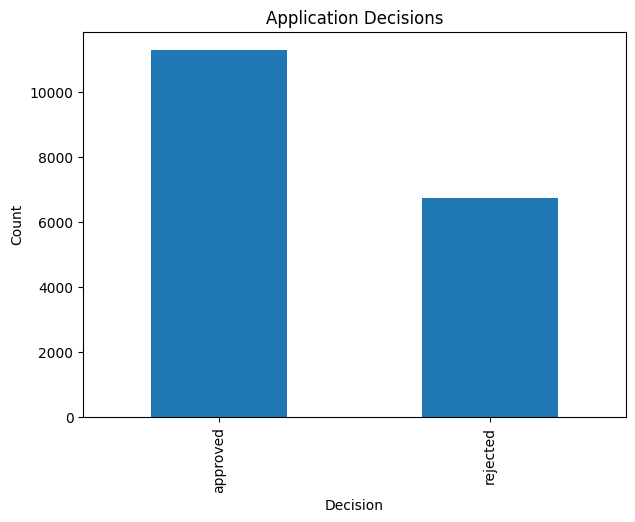


Rejected applications: 6723


,application_id,client_id,decision_date,channel,purpose,requested_amount_uzs,term_months,declared_income_uzs,employment_months,final_decision,approved_by_old_policy
3,4,23494,2024-12-04,agent,medical,15500000,9,4340000,155.0,rejected,False
4,5,29522,2023-07-13,branch,consumer,14800000,18,3120000,57.0,rejected,False
5,6,4526,2025-01-16,branch,education,2200000,6,17300000,124.0,rejected,True
7,8,22551,2024-11-24,branch,repair,9100000,12,4950000,217.0,rejected,False
8,9,2271,2025-04-06,agent,auto,33500000,12,24090000,143.0,rejected,True



Columns


,Column,Data type
application_id,application_id,int64
client_id,client_id,int64
decision_date,decision_date,object
channel,channel,object
purpose,purpose,object
requested_amount_uzs,requested_amount_uzs,int64
term_months,term_months,int64
declared_income_uzs,declared_income_uzs,int64
employment_months,employment_months,float64
final_decision,final_decision,object



Missing values


...

approved_by_old_policy
False    6111
True      612
Name: count, dtype: int64


Sample rejected applications


,application_id,client_id,decision_date,channel,purpose,requested_amount_uzs,term_months,declared_income_uzs,employment_months,final_decision,approved_by_old_policy
15251,15252,31787,2024-04-29,agent,education,6700000,24,4230000,92.0,rejected,False
9332,9333,24484,2023-10-18,branch,auto,8300000,12,2220000,205.0,rejected,False
10958,10959,25443,2024-08-04,mobile_app,other,7800000,12,4800000,185.0,rejected,False
7178,7179,3103,2024-03-13,mobile_app,medical,3200000,6,6910000,107.0,rejected,True
5153,5154,5473,2025-04-05,branch,auto,8400000,18,9290000,12.0,rejected,False
1470,1471,27029,2025-03-22,mobile_app,education,3400000,12,2630000,135.0,rejected,False
1490,1491,7387,2024-07-20,branch,consumer,6500000,18,22460000,NaN,rejected,False
3808,3809,1322,2023-06-25,mobile_app,education,22100000,12,15670000,NaN,rejected,True
17989,17990,6094,2024-08-17,branch,education,20500000,6,20580000,240.0,rejected,False
14625,14626,4567,2024-08-31,branch,auto,5000000,12,2000000,202.0,rejected,False



Approved vs Rejected


,Approved Mean,Rejected Mean
requested_amount_uzs,1.371827e+07,1.077916e+07
declared_income_uzs,1.019249e+07,6.384541e+06
employment_months,1.203259e+02,1.209360e+02


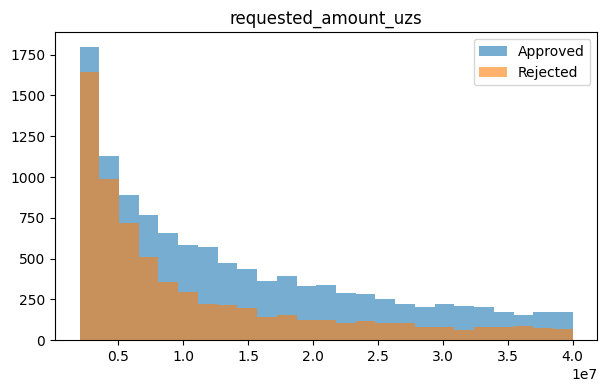

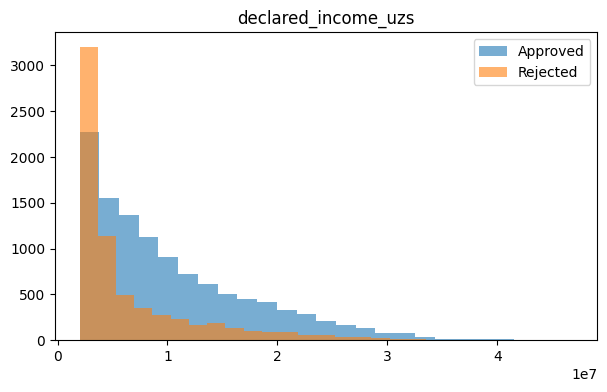

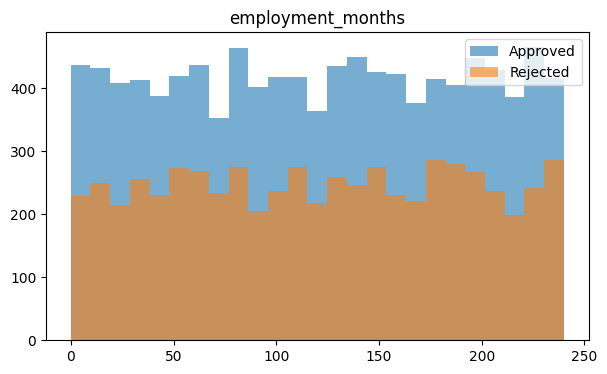


FINAL REPORT


,Metric,Value,Interpretation
0,Applications table,scoring_applications,Loan applications
1,Decision column,final_decision,Target variable
2,Total applications,18000,Number of applications
3,Approved applications,11277,Applications approved
4,Rejected applications,6723,Applications rejected
5,Approval rate,62.65%,Approval percentage
6,Rejection rate,37.35%,Rejection percentage


In [79]:
# =====================================================================================
# APPLICATION APPROVAL / REJECTION ANALYSIS
# =====================================================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)

# -------------------------------------------------------------------------------------
# LOAD APPLICATIONS
# -------------------------------------------------------------------------------------

applications = q('SELECT * FROM "scoring_applications"')

print("Applications shape:", applications.shape)

display(applications.head())

# -------------------------------------------------------------------------------------
# APPLICATION STATUS
# -------------------------------------------------------------------------------------

status_col = "final_decision"

print("\nStatus distribution:")

display(
    applications[status_col]
    .value_counts(dropna=False)
    .rename_axis("Status")
    .reset_index(name="Count")
)

# ------------------------------------------------------------------------------
# CHANGE THESE VALUES IF YOUR DATA USES DIFFERENT LABELS
# ------------------------------------------------------------------------------

approved_mask = applications["final_decision"] == "approved"
rejected_mask = applications["final_decision"] == "rejected"

# -------------------------------------------------------------------------------------
# BASIC METRICS
# -------------------------------------------------------------------------------------

total = len(applications)
approved = approved_mask.sum()
rejected = rejected_mask.sum()

approval_rate = approved / total * 100
rejection_rate = rejected / total * 100

summary = pd.DataFrame({

    "Metric":[
        "Total applications",
        "Approved applications",
        "Rejected applications",
        "Approval rate",
        "Rejection rate"
    ],

    "Value":[
        total,
        approved,
        rejected,
        f"{approval_rate:.2f}%",
        f"{rejection_rate:.2f}%"
    ],

    "Interpretation":[
        "All submitted applications",
        "Applications approved",
        "Applications rejected",
        "Share of approved applications",
        "Share of rejected applications"
    ]

})

display(summary)

# -------------------------------------------------------------------------------------
# STATUS DISTRIBUTION
# -------------------------------------------------------------------------------------

plt.figure(figsize=(7,5))

applications[status_col].value_counts().plot(kind="bar")

plt.title("Application Decisions")
plt.xlabel("Decision")
plt.ylabel("Count")

plt.show()

# -------------------------------------------------------------------------------------
# REJECTED APPLICATIONS
# -------------------------------------------------------------------------------------

rejected_df = applications.loc[rejected_mask].copy()

print("\nRejected applications:", len(rejected_df))

display(rejected_df.head())

# -------------------------------------------------------------------------------------
# AVAILABLE COLUMNS
# -------------------------------------------------------------------------------------

print("\nColumns")

display(pd.DataFrame({

    "Column": rejected_df.columns,

    "Data type": rejected_df.dtypes.astype(str)

}))

# -------------------------------------------------------------------------------------
# MISSING VALUES
# -------------------------------------------------------------------------------------

missing = pd.DataFrame({

    "Column": rejected_df.columns,

    "Missing": rejected_df.isna().sum().values,

    "Percent": (
        rejected_df.isna().mean()*100
    ).round(2)

})

print("\nMissing values")

display(
    missing.sort_values(
        "Percent",
        ascending=False
    )
)

# -------------------------------------------------------------------------------------
# NUMERIC SUMMARY
# -------------------------------------------------------------------------------------

print("\nNumeric statistics")

display(
    rejected_df.describe().T
)

# -------------------------------------------------------------------------------------
# CATEGORICAL VARIABLES
# -------------------------------------------------------------------------------------

categorical = rejected_df.select_dtypes(
    include=["object","bool","category"]
)

for col in categorical.columns:

    print("\n", "="*80)
    print(col)
    print("="*80)

    display(
        rejected_df[col]
        .value_counts(dropna=False)
    )

# -------------------------------------------------------------------------------------
# SAMPLE REJECTED APPLICATIONS
# -------------------------------------------------------------------------------------

print("\nSample rejected applications")

display(
    rejected_df.sample(
        min(10, len(rejected_df)),
        random_state=42
    )
)

# -------------------------------------------------------------------------------------
# APPROVED VS REJECTED COMPARISON
# -------------------------------------------------------------------------------------

comparison_columns = [

    "requested_amount_uzs",

    "declared_income_uzs",

    "employment_months"

]

comparison = pd.DataFrame({

    "Approved Mean":[
        applications.loc[approved_mask, c].mean()
        for c in comparison_columns
    ],

    "Rejected Mean":[
        applications.loc[rejected_mask, c].mean()
        for c in comparison_columns
    ]

},
index=comparison_columns)

print("\nApproved vs Rejected")

display(comparison)

# -------------------------------------------------------------------------------------
# HISTOGRAMS
# -------------------------------------------------------------------------------------

for col in comparison_columns:

    plt.figure(figsize=(7,4))

    plt.hist(
        applications.loc[
            approved_mask,
            col
        ].dropna(),
        bins=25,
        alpha=0.6,
        label="Approved"
    )

    plt.hist(
        applications.loc[
            rejected_mask,
            col
        ].dropna(),
        bins=25,
        alpha=0.6,
        label="Rejected"
    )

    plt.title(col)

    plt.legend()

    plt.show()

# -------------------------------------------------------------------------------------
# FINAL REPORT
# -------------------------------------------------------------------------------------

final_report = pd.DataFrame({

    "Metric":[

        "Applications table",

        "Decision column",

        "Total applications",

        "Approved applications",

        "Rejected applications",

        "Approval rate",

        "Rejection rate"

    ],

    "Value":[

        "scoring_applications",

        "final_decision",

        total,

        approved,

        rejected,

        f"{approval_rate:.2f}%",

        f"{rejection_rate:.2f}%"

    ],

    "Interpretation":[

        "Loan applications",

        "Target variable",

        "Number of applications",

        "Applications approved",

        "Applications rejected",

        "Approval percentage",

        "Rejection percentage"

    ]

})

print("\nFINAL REPORT")

display(final_report)

In [80]:
# =====================================================================================
# CONTRACT OBSERVATION WINDOW ANALYSIS
# =====================================================================================

import pandas as pd
import numpy as np

contracts = q("SELECT * FROM scoring_contracts")

print("Contracts table")
print(contracts.shape)

display(contracts.head())

# =====================================================================================
# IDENTIFY DATE COLUMNS
# =====================================================================================

date_columns = []

for col in contracts.columns:

    if (
        "date" in col.lower()
        or "time" in col.lower()
    ):

        date_columns.append(col)

print("\nDate columns detected:")

print(date_columns)

# =====================================================================================
# OBSERVATION PERIOD
# =====================================================================================

date_summary = []

for col in date_columns:

    d = pd.to_datetime(
        contracts[col],
        errors="coerce"
    )

    date_summary.append({

        "column": col,

        "minimum": d.min(),

        "maximum": d.max()

    })

date_summary = pd.DataFrame(date_summary)

display(date_summary)

latest_observation = date_summary["maximum"].max()

print("\nLatest observed date:")

print(latest_observation)

# =====================================================================================
# CHECK AVAILABLE INFORMATION
# =====================================================================================

required_columns = [

    "close_date",

    "end_date",

    "termination_date",

    "maturity_date",

    "status",

    "snapshot_date"

]

missing_columns = [

    c for c in required_columns

    if c not in contracts.columns

]

print("\nMissing columns")

print(missing_columns)

# =====================================================================================
# ESTIMATE MATURITY DATE
# =====================================================================================

contracts["estimated_maturity_date"] = (

    pd.to_datetime(contracts["issue_date"])

    +

    contracts["term_months"]

    .fillna(0)

    .astype(int)

    .apply(lambda x: pd.DateOffset(months=x))

)

# =====================================================================================
# ESTIMATE OPEN CONTRACTS
# =====================================================================================

contracts["observation_status"] = np.where(

    contracts["estimated_maturity_date"] > latest_observation,

    "Open",

    "Closed"

)

contracts["evidence"] = np.where(

    contracts["estimated_maturity_date"] > latest_observation,

    "Estimated maturity is after latest observed issue date.",

    "Estimated maturity is before latest observed issue date."

)

contracts["should_be_used_for_model_training"] = np.where(

    contracts["observation_status"] == "Closed",

    "Yes",

    "No"

)

contracts["explanation"] = np.where(

    contracts["observation_status"] == "Closed",

    "Estimated observation window appears complete.",

    "Observation window may still be incomplete."

)

# =====================================================================================
# SUMMARY
# =====================================================================================

total = len(contracts)

closed = (contracts["observation_status"] == "Closed").sum()

open_ = (contracts["observation_status"] == "Open").sum()

print("\nSummary")

summary = pd.DataFrame({

    "Metric":[

        "Total contracts",

        "Closed observation window",

        "Open observation window",

        "Incomplete percentage"

    ],

    "Value":[

        total,

        closed,

        open_,

        f"{open_/total*100:.2f}%"

    ]

})

display(summary)

# =====================================================================================
# OPEN CONTRACTS
# =====================================================================================

print("\nContracts with potentially incomplete observation windows")

display(

    contracts.loc[

        contracts["observation_status"] == "Open",

        [

            "contract_id",

            "client_id",

            "issue_date",

            "estimated_maturity_date",

            "issued_amount_uzs",

            "term_months",

            "observation_status",

            "evidence"

        ]

    ]

)

# =====================================================================================
# FINAL REPORT
# =====================================================================================

final_report = contracts[

    [

        "contract_id",

        "observation_status",

        "evidence",

        "should_be_used_for_model_training",

        "explanation"

    ]

]

display(final_report)

# =====================================================================================
# LIMITATION
# =====================================================================================

if len(missing_columns):

    print("\nIMPORTANT")

    print(
        "The dataset does not contain enough information "
        "to determine observation windows with certainty."
    )

    print("\nMissing columns:")

    print(missing_columns)

    print(
        "\nThe analysis above is an estimate based on "
        "issue_date + term_months."
    )

Contracts table
(11277, 8)


,contract_id,application_id,client_id,issue_date,issued_amount_uzs,term_months,annual_rate_pct,monthly_payment_uzs
0,1,1,529,2024-08-30,17600000,18,24.2,1175677
1,2,2,920,2023-10-21,11400000,12,33.6,1131637
2,3,3,7509,2023-07-02,3200000,12,35.0,319881
3,4,7,4522,2024-06-20,5600000,9,32.9,710591
4,5,10,7478,2025-03-03,2100000,24,35.4,123332



Date columns detected:
['issue_date']


,column,minimum,maximum
0,issue_date,2023-06-02,2025-05-05



Latest observed date:
2025-05-05 00:00:00

Missing columns
['close_date', 'end_date', 'termination_date', 'maturity_date', 'status', 'snapshot_date']


...

,Metric,Value
0,Total contracts,11277
1,Closed observation window,4778
2,Open observation window,6499
3,Incomplete percentage,57.63%



Contracts with potentially incomplete observation windows


,contract_id,client_id,issue_date,estimated_maturity_date,issued_amount_uzs,term_months,observation_status,evidence
0,1,529,2024-08-30,2026-02-28 00:00:00,17600000,18,Open,Estimated maturity is after latest observed issue date.
4,5,7478,2025-03-03,2027-03-03 00:00:00,2100000,24,Open,Estimated maturity is after latest observed issue date.
8,9,1919,2024-05-20,2025-11-20 00:00:00,6600000,18,Open,Estimated maturity is after latest observed issue date.
10,11,21278,2024-11-29,2026-05-29 00:00:00,3200000,18,Open,Estimated maturity is after latest observed issue date.
12,13,640,2024-10-21,2025-10-21 00:00:00,25500000,12,Open,Estimated maturity is after latest observed issue date.
...,...,...,...,...,...,...,...,...
11268,11269,20463,2025-02-06,2026-02-06 00:00:00,16900000,12,Open,Estimated maturity is after latest observed issue date.
11271,11272,26775,2024-06-04,2025-06-04 00:00:00,1900000,12,Open,Estimated maturity is after latest observed issue date.
11273,11274,20558,2024-07-14,2025-07-14 00:00:00,36100000,12,Open,Estimated maturity is after latest observed issue date.
11274,11275,21276,2024-10-05,2025-07-05 00:00:00,12700000,9,Open,Estimated maturity is after latest observed issue date.


,contract_id,observation_status,evidence,should_be_used_for_model_training,explanation
0,1,Open,Estimated maturity is after latest observed issue date.,No,Observation window may still be incomplete.
1,2,Closed,Estimated maturity is before latest observed issue date.,Yes,Estimated observation window appears complete.
2,3,Closed,Estimated maturity is before latest observed issue date.,Yes,Estimated observation window appears complete.
3,4,Closed,Estimated maturity is before latest observed issue date.,Yes,Estimated observation window appears complete.
4,5,Open,Estimated maturity is after latest observed issue date.,No,Observation window may still be incomplete.
...,...,...,...,...,...
11272,11273,Closed,Estimated maturity is before latest observed issue date.,Yes,Estimated observation window appears complete.
11273,11274,Open,Estimated maturity is after latest observed issue date.,No,Observation window may still be incomplete.
11274,11275,Open,Estimated maturity is after latest observed issue date.,No,Observation window may still be incomplete.
11275,11276,Closed,Estimated maturity is before latest observed issue date.,Yes,Estimated observation window appears complete.



IMPORTANT
The dataset does not contain enough information to determine observation windows with certainty.

Missing columns:
['close_date', 'end_date', 'termination_date', 'maturity_date', 'status', 'snapshot_date']

The analysis above is an estimate based on issue_date + term_months.


In [81]:
# =====================================================================================
# TARGET LEAKAGE DETECTION FOR ALL scoring_* TABLES
# =====================================================================================

import pandas as pd
import numpy as np

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)

# =====================================================================================
# DISCOVER ALL scoring_ TABLES
# =====================================================================================

tables = q("""
SELECT tablename
FROM pg_tables
WHERE schemaname='public'
AND tablename LIKE 'scoring\\_%'
ORDER BY tablename
""")["tablename"].tolist()

print(f"Found {len(tables)} scoring tables.")

# =====================================================================================
# KEYWORDS
# =====================================================================================

before_keywords = [

    "application",
    "client",
    "customer",
    "income",
    "employment",
    "salary",
    "requested",
    "amount",
    "purpose",
    "channel",
    "term",
    "bureau",
    "score",
    "age",
    "gender",
    "region",
    "city",
    "education"

]

leakage_keywords = [

    "default",
    "delin",
    "overdue",
    "dpd",
    "payment",
    "paid",
    "collection",
    "recover",
    "recovery",
    "write_off",
    "writeoff",
    "charge_off",
    "chargeoff",
    "loss",
    "close",
    "closed",
    "termination",
    "repayment",
    "fraud",
    "dispute",
    "outcome",
    "status",
    "decision",
    "approved",
    "approval",
    "issued",
    "charge",
    "penalty"

]

# =====================================================================================
# KNOWN LEAKAGE COLUMNS IN THIS DATASET
# =====================================================================================

known_leakage = {

    "scoring_applications": {

        "final_decision":
            "Target variable containing the final loan decision.",

        "approved_by_old_policy":
            "Decision produced by a previous approval policy."
    }

}

# =====================================================================================
# ANALYZE TABLES
# =====================================================================================

results = []

for table in tables:

    print("\n" + "="*120)
    print(table.upper())
    print("="*120)

    df = q(f'SELECT * FROM "{table}" LIMIT 5')

    display(df)

    print("\nColumns:")

    print(list(df.columns))

    for column in df.columns:

        col = column.lower()

        suspected = "No"
        reason = "Available before credit decision."
        feature = "Yes"

        # ---------------------------------------------------------------------
        # Known leakage
        # ---------------------------------------------------------------------

        if (
            table in known_leakage
            and column in known_leakage[table]
        ):

            suspected = "Yes"

            feature = "No"

            reason = known_leakage[table][column]

        # ---------------------------------------------------------------------
        # Detect by keyword
        # ---------------------------------------------------------------------

        elif any(k in col for k in leakage_keywords):

            suspected = "Yes"

            feature = "No"

            reason = (
                "Column appears to describe events "
                "after the credit decision."
            )

        # ---------------------------------------------------------------------
        # Detect uncertain columns
        # ---------------------------------------------------------------------

        elif (
            "date" in col
            or "time" in col
        ):

            suspected = "Uncertain"

            feature = "Review"

            reason = (
                "Date column. Verify whether it is known "
                "before the decision."
            )

        elif any(k in col for k in before_keywords):

            suspected = "No"

            feature = "Yes"

            reason = (
                "Applicant information available "
                "before the decision."
            )

        else:

            suspected = "Uncertain"

            feature = "Review"

            reason = (
                "Cannot determine automatically."
            )

        results.append({

            "table_name": table,

            "column_name": column,

            "suspected_leakage": suspected,

            "reason": reason,

            "can_be_used_for_features": feature

        })

# =====================================================================================
# FINAL RESULTS
# =====================================================================================

leakage_df = pd.DataFrame(results)

print("\nTARGET LEAKAGE SUMMARY")

display(leakage_df)

# =====================================================================================
# ONLY LEAKAGE COLUMNS
# =====================================================================================

print("\nColumns that should NOT be used as model features")

excluded = leakage_df[
    leakage_df["can_be_used_for_features"] == "No"
].copy()

display(excluded)

# =====================================================================================
# CONCISE CONCLUSION
# =====================================================================================

print("\n" + "="*120)
print("CONCLUSION")
print("="*120)

if excluded.empty:

    print("No obvious target leakage columns were detected automatically.")

else:

    for _, row in excluded.iterrows():

        print(
            f"- {row['table_name']}.{row['column_name']}: "
            f"{row['reason']}"
        )

# =====================================================================================
# SAVE RESULTS
# =====================================================================================

leakage_df.to_csv(
    "target_leakage_summary.csv",
    index=False
)

print("\nResults saved as 'target_leakage_summary.csv'.")

Found 17 scoring tables.

SCORING_APPLICATIONS


,application_id,client_id,decision_date,channel,purpose,requested_amount_uzs,term_months,declared_income_uzs,employment_months,final_decision,approved_by_old_policy
0,1,529,2024-08-27,mobile_app,education,20800000,18,6310000,204,approved,True
1,2,920,2023-10-19,branch,education,15300000,12,11120000,0,approved,True
2,3,7509,2023-07-01,branch,education,3900000,12,4140000,92,approved,True
3,4,23494,2024-12-04,agent,medical,15500000,9,4340000,155,rejected,False
4,5,29522,2023-07-13,branch,consumer,14800000,18,3120000,57,rejected,False



Columns:
['application_id', 'client_id', 'decision_date', 'channel', 'purpose', 'requested_amount_uzs', 'term_months', 'declared_income_uzs', 'employment_months', 'final_decision', 'approved_by_old_policy']

SCORING_APPLICATIONS_FULL


,application_id,client_id,decision_date,requested_amount_uzs,term_months,declared_income_uzs,bureau_score_latest,dpd_max,collection_calls_cnt,contract_status_now
0,1,529,2024-08-27,20800000,18,6310000,611,7,0,active
1,2,920,2023-10-19,15300000,12,11120000,670,12,0,closed
2,3,7509,2023-07-01,3900000,12,4140000,681,7,0,closed
3,7,4522,2024-06-17,6100000,9,4500000,718,65,1,delinq_30plus
4,10,7478,2025-02-28,2500000,24,14620000,687,7,0,active



Columns:
['application_id', 'client_id', 'decision_date', 'requested_amount_uzs', 'term_months', 'declared_income_uzs', 'bureau_score_latest', 'dpd_max', 'collection_calls_cnt', 'contract_status_now']

SCORING_BUREAU_INQUIRIES


...


Columns:
['transaction_id', 'card_id', 'merchant_id', 'terminal_id', 'txn_ts', 'amount_uzs', 'txn_status', 'decline_reason', 'is_recurring', 'entry_mode', 'is_disputed']

TARGET LEAKAGE SUMMARY


,table_name,column_name,suspected_leakage,reason,can_be_used_for_features
0,scoring_applications,application_id,No,Applicant information available before the decision.,Yes
1,scoring_applications,client_id,No,Applicant information available before the decision.,Yes
2,scoring_applications,decision_date,Yes,Column appears to describe events after the credit decision.,No
3,scoring_applications,channel,No,Applicant information available before the decision.,Yes
4,scoring_applications,purpose,No,Applicant information available before the decision.,Yes
5,scoring_applications,requested_amount_uzs,No,Applicant information available before the decision.,Yes
6,scoring_applications,term_months,No,Applicant information available before the decision.,Yes
7,scoring_applications,declared_income_uzs,No,Applicant information available before the decision.,Yes
8,scoring_applications,employment_months,No,Applicant information available before the decision.,Yes
9,scoring_applications,final_decision,Yes,Target variable containing the final loan decision.,No



Columns that should NOT be used as model features


,table_name,column_name,suspected_leakage,reason,can_be_used_for_features
2,scoring_applications,decision_date,Yes,Column appears to describe events after the credit decision.,No
9,scoring_applications,final_decision,Yes,Target variable containing the final loan decision.,No
10,scoring_applications,approved_by_old_policy,Yes,Decision produced by a previous approval policy.,No
13,scoring_applications_full,decision_date,Yes,Column appears to describe events after the credit decision.,No
18,scoring_applications_full,dpd_max,Yes,Column appears to describe events after the credit decision.,No
19,scoring_applications_full,collection_calls_cnt,Yes,Column appears to describe events after the credit decision.,No
20,scoring_applications_full,contract_status_now,Yes,Column appears to describe events after the credit decision.,No
30,scoring_bureau_loans,planned_close_date,Yes,Column appears to describe events after the credit decision.,No
31,scoring_bureau_loans,close_date,Yes,Column appears to describe events after the credit decision.,No
33,scoring_bureau_loans,monthly_payment_uzs,Yes,Column appears to describe events after the credit decision.,No



CONCLUSION
- scoring_applications.decision_date: Column appears to describe events after the credit decision.
- scoring_applications.final_decision: Target variable containing the final loan decision.
- scoring_applications.approved_by_old_policy: Decision produced by a previous approval policy.
- scoring_applications_full.decision_date: Column appears to describe events after the credit decision.
- scoring_applications_full.dpd_max: Column appears to describe events after the credit decision.
- scoring_applications_full.collection_calls_cnt: Column appears to describe events after the credit decision.
- scoring_applications_full.contract_status_now: Column appears to describe events after the credit decision.
- scoring_bureau_loans.planned_close_date: Column appears to describe events after the credit decision.
- scoring_bureau_loans.close_date: Column appears to describe events after the credit decision.
- scoring_bureau_loans.monthly_payment_uzs: Column appears to describe events a

In [82]:
# =====================================================================================
# COLLECT METADATA
# =====================================================================================

metadata = {}

for table in tables:

    print(f"Reading metadata: {table}")

    sample = q(f'SELECT * FROM "{table}" LIMIT 1000')

    row_count = q(f'SELECT COUNT(*) AS cnt FROM "{table}"').iloc[0]["cnt"]

    missing_pct = (
        sample.isna()
        .mean()
        .mul(100)
        .round(2)
        .to_dict()
    )

    pk_candidates = []

    for col in sample.columns:

        if (
            col.lower().endswith("_id")
            or col.lower() == "id"
        ):

            if sample[col].nunique(dropna=False) == len(sample):

                pk_candidates.append(col)

    metadata[table] = {

        "columns": list(sample.columns),

        "column_set": set(sample.columns),

        "types": sample.dtypes.astype(str).to_dict(),

        "rows": row_count,

        "cols": sample.shape[1],

        "pk": pk_candidates,

        "missing": missing_pct

    }

# =====================================================================================
# COMPARE TABLES
# =====================================================================================

comparison = []

for i in range(len(tables)):

    for j in range(i + 1, len(tables)):

        t1 = tables[i]
        t2 = tables[j]

        m1 = metadata[t1]
        m2 = metadata[t2]

        common_cols = m1["column_set"] & m2["column_set"]
        all_cols = m1["column_set"] | m2["column_set"]

        similarity = round(
            len(common_cols) / max(len(all_cols), 1) * 100,
            2
        )

        # ---------------------------------------------------------------------
        # Compare data types
        # ---------------------------------------------------------------------

        matching_types = 0

        for col in common_cols:

            if m1["types"][col] == m2["types"][col]:

                matching_types += 1

        # ---------------------------------------------------------------------
        # Shared PKs
        # ---------------------------------------------------------------------

        shared_pk = list(set(m1["pk"]) & set(m2["pk"]))

        # ---------------------------------------------------------------------
        # Missing values
        # ---------------------------------------------------------------------

        common_missing = []

        for col in common_cols:

            diff = abs(

                m1["missing"].get(col, 0)

                -

                m2["missing"].get(col, 0)

            )

            common_missing.append(diff)

        avg_missing_difference = round(

            np.mean(common_missing),

            2

        ) if common_missing else 0

        # ---------------------------------------------------------------------
        # Relationship
        # ---------------------------------------------------------------------

        relationship = "Different"

        if similarity == 100:

            relationship = "Duplicate"

        elif m1["column_set"].issubset(m2["column_set"]):

            relationship = "Subset"

        elif m2["column_set"].issubset(m1["column_set"]):

            relationship = "Subset"

        # ---------------------------------------------------------------------
        # Detect version names
        # ---------------------------------------------------------------------

        version_words = [

            "_full",
            "_old",
            "_backup",
            "_copy",
            "_temp",
            "_sample",
            "_v2",
            "_v3"

        ]

        version_detected = any(

            word in t1.lower() or word in t2.lower()

            for word in version_words

        )

        # ---------------------------------------------------------------------
        # Recommend table
        # ---------------------------------------------------------------------

        score1 = m1["rows"] + (m1["cols"] * 100)
        score2 = m2["rows"] + (m2["cols"] * 100)

        if score1 >= score2:

            recommended = t1

        else:

            recommended = t2

        reason = []

        if m1["rows"] != m2["rows"]:

            reason.append("More rows")

        if m1["cols"] != m2["cols"]:

            reason.append("More columns")

        if version_detected:

            reason.append("Version naming detected")

        if relationship == "Duplicate":

            reason.append("Identical schema")

        if relationship == "Subset":

            reason.append("One schema is contained in the other")

        comparison.append({

            "table_1": t1,

            "table_2": t2,

            "similarity_percentage": similarity,

            "relationship": relationship,

            "recommended_table": recommended,

            "reason": "; ".join(reason),

            "shared_primary_keys": ", ".join(shared_pk),

            "rows_table_1": m1["rows"],

            "rows_table_2": m2["rows"],

            "columns_table_1": m1["cols"],

            "columns_table_2": m2["cols"],

            "matching_data_types": matching_types,

            "average_missing_difference": avg_missing_difference

        })

# =====================================================================================
# SUMMARY
# =====================================================================================

comparison_df = pd.DataFrame(comparison)

comparison_df = comparison_df.sort_values(

    "similarity_percentage",

    ascending=False

)

print("=" * 120)
print("TABLE COMPARISON SUMMARY")
print("=" * 120)

display(comparison_df)

# =====================================================================================
# HIGHLY SIMILAR TABLES
# =====================================================================================

duplicates = comparison_df[
    comparison_df["similarity_percentage"] >= 80
].copy()

print("\nHighly similar tables (>=80%)")

display(duplicates)

# =====================================================================================
# FINAL RECOMMENDATIONS
# =====================================================================================

print("\n" + "=" * 120)
print("FINAL RECOMMENDATIONS")
print("=" * 120)

recommended_tables = sorted(
    duplicates["recommended_table"].unique()
)

ignored_tables = sorted(
    set(
        duplicates["table_1"]
    ).union(
        duplicates["table_2"]
    ) - set(recommended_tables)
)

print("\nTABLES TO USE")

for t in recommended_tables:

    print(f"✔ {t}")

print("\nTABLES TO IGNORE")

for t in ignored_tables:

    print(f"✖ {t}")

print("\nJUSTIFICATION")

for _, row in duplicates.iterrows():

    print(
        f"- {row['recommended_table']} is preferred over "
        f"{row['table_1'] if row['recommended_table'] != row['table_1'] else row['table_2']} "
        f"because: {row['reason']}"
    )

# =====================================================================================
# EXPORT RESULTS
# =====================================================================================

comparison_df.to_csv(
    "duplicate_table_analysis.csv",
    index=False
)

print("\nAnalysis saved to 'duplicate_table_analysis.csv'.")

Reading metadata: scoring_applications
Reading metadata: scoring_applications_full
Reading metadata: scoring_bureau_inquiries
Reading metadata: scoring_bureau_loans
Reading metadata: scoring_bureau_snapshots
Reading metadata: scoring_card_disputes
Reading metadata: scoring_card_transactions
Reading metadata: scoring_cards
Reading metadata: scoring_clients_old
Reading metadata: scoring_collection_actions
Reading metadata: scoring_contracts
Reading metadata: scoring_customers
Reading metadata: scoring_model_v1_scores
Reading metadata: scoring_payments
Reading metadata: scoring_payments_backup
Reading metadata: scoring_temp
Reading metadata: scoring_txn_sample
TABLE COMPARISON SUMMARY


,table_1,table_2,similarity_percentage,relationship,recommended_table,reason,shared_primary_keys,rows_table_1,rows_table_2,columns_table_1,columns_table_2,matching_data_types,average_missing_difference
130,scoring_payments,scoring_payments_backup,100.00,Duplicate,scoring_payments,More rows; Version naming detected; Identical schema,payment_id,103150,73421,7,7,7,0.14
0,scoring_applications,scoring_applications_full,40.00,Different,scoring_applications,More rows; More columns; Version naming detected,application_id,18000,11277,11,10,6,0.00
90,scoring_card_transactions,scoring_txn_sample,25.00,Different,scoring_card_transactions,More rows; More columns; Version naming detected,,1044743,5000,9,11,4,0.15
24,scoring_applications_full,scoring_contracts,20.00,Different,scoring_applications_full,More columns; Version naming detected,application_id,11277,11277,10,8,3,0.00
9,scoring_applications,scoring_contracts,18.75,Different,scoring_applications,More rows; More columns,application_id,18000,11277,11,8,3,0.00
70,scoring_card_disputes,scoring_card_transactions,15.38,Different,scoring_card_transactions,More rows; More columns,txn_id,2467,1044743,6,9,2,0.00
81,scoring_card_transactions,scoring_cards,13.33,Different,scoring_card_transactions,More rows; More columns,,1044743,12614,9,8,2,0.00
31,scoring_bureau_inquiries,scoring_bureau_loans,13.33,Different,scoring_bureau_loans,More rows; More columns,,31383,34684,5,12,2,0.00
32,scoring_bureau_inquiries,scoring_bureau_snapshots,11.11,Different,scoring_bureau_snapshots,More rows,,31383,86161,5,5,1,0.00
51,scoring_bureau_loans,scoring_contracts,11.11,Different,scoring_bureau_loans,More rows; More columns,,34684,11277,12,8,2,0.00



Highly similar tables (>=80%)


,table_1,table_2,similarity_percentage,relationship,recommended_table,reason,shared_primary_keys,rows_table_1,rows_table_2,columns_table_1,columns_table_2,matching_data_types,average_missing_difference
130,scoring_payments,scoring_payments_backup,100.0,Duplicate,scoring_payments,More rows; Version naming detected; Identical schema,payment_id,103150,73421,7,7,7,0.14



FINAL RECOMMENDATIONS

TABLES TO USE
✔ scoring_payments

TABLES TO IGNORE
✖ scoring_payments_backup

JUSTIFICATION
- scoring_payments is preferred over scoring_payments_backup because: More rows; Version naming detected; Identical schema

Analysis saved to 'duplicate_table_analysis.csv'.


In [83]:
# =====================================================================================
# LOAD TABLES
# =====================================================================================

customers = q("SELECT * FROM scoring_customers")
cards = q("SELECT * FROM scoring_cards")
transactions = q("SELECT * FROM scoring_card_transactions")

print("Customers:", customers.shape)
print("Cards:", cards.shape)
print("Transactions:", transactions.shape)

# =====================================================================================
# CHECK WHETHER customer_id == client_id
# =====================================================================================

customer_key = "customer_id"

if "client_id" in transactions.columns:

    overlap = len(
        set(customers["customer_id"])
        &
        set(transactions["client_id"])
    )

    print(f"Matching IDs between customer_id and client_id: {overlap}")

# =====================================================================================
# PREPARE TRANSACTIONS
# =====================================================================================

transactions["txn_ts"] = pd.to_datetime(
    transactions["txn_ts"],
    errors="coerce"
)

txn_summary = (

    transactions

    .groupby("card_id")

    .agg(

        transaction_count=("txn_id", "count"),

        first_transaction=("txn_ts", "min"),

        last_transaction=("txn_ts", "max")

    )

    .reset_index()

)

# =====================================================================================
# JOIN CUSTOMERS -> CARDS
# =====================================================================================

customer_cards = customers.merge(

    cards,

    on="customer_id",

    how="left"

)

# =====================================================================================
# JOIN CARD TRANSACTIONS
# =====================================================================================

customer_data = customer_cards.merge(

    txn_summary,

    on="card_id",

    how="left"

)

# =====================================================================================
# FLAGS
# =====================================================================================

customer_data["has_card"] = np.where(

    customer_data["card_id"].notna(),

    "Yes",

    "No"

)

customer_data["has_transactions"] = np.where(

    customer_data["transaction_count"].fillna(0) > 0,

    "Yes",

    "No"

)

customer_data["transaction_count"] = (

    customer_data["transaction_count"]

    .fillna(0)

    .astype(int)

)

# =====================================================================================
# POSSIBLE REASONS FOR NO TRANSACTIONS
# =====================================================================================

def reason(row):

    if pd.isna(row["card_id"]):
        return "No issued card"

    status = str(row["status"]).lower()

    if status != "active":
        return f"Card status: {row['status']}"

    if pd.notna(row["expiry_date"]):

        expiry = pd.to_datetime(row["expiry_date"])

        if expiry < pd.Timestamp.today():

            return "Card expired"

    if row["transaction_count"] == 0:
        return "No recorded transactions"

    return "Has transactions"

customer_data["possible_reason_no_transactions"] = (

    customer_data.apply(reason, axis=1)

)

# =====================================================================================
# CUSTOMER SUMMARY
# =====================================================================================

summary = customer_data[[

    "customer_id",

    "has_card",

    "has_transactions",

    "transaction_count",

    "possible_reason_no_transactions"

]]

display(summary)

# =====================================================================================
# OVERALL STATISTICS
# =====================================================================================

total_customers = customers["customer_id"].nunique()

with_transactions = (

    summary["has_transactions"] == "Yes"

).sum()

without_transactions = (

    summary["has_transactions"] == "No"

).sum()

stats = pd.DataFrame({

    "Metric":[

        "Total customers",

        "Customers with transactions",

        "Customers without transactions",

        "Percentage with transactions",

        "Percentage without transactions"

    ],

    "Value":[

        total_customers,

        with_transactions,

        without_transactions,

        f"{with_transactions/total_customers*100:.2f}%",

        f"{without_transactions/total_customers*100:.2f}%"

    ]

})

print("\nOVERALL STATISTICS")

display(stats)

# =====================================================================================
# REASONS
# =====================================================================================

reason_report = (

    summary

    .groupby("possible_reason_no_transactions")

    .size()

    .reset_index(name="number_of_customers")

)

reason_report["percentage_of_customers"] = (

    reason_report["number_of_customers"]

    / total_customers

    * 100

).round(2)

reason_report.rename(

    columns={

        "possible_reason_no_transactions":"reason"

    },

    inplace=True

)

print("\nREASONS FOR NO TRANSACTIONS")

display(reason_report)

# =====================================================================================
# CUSTOMERS WITH TRANSACTIONS
# =====================================================================================

print("\nCUSTOMERS WITH TRANSACTIONS")

display(

    summary[

        summary["has_transactions"]=="Yes"

    ]

)

# =====================================================================================
# CUSTOMERS WITHOUT TRANSACTIONS
# =====================================================================================

print("\nCUSTOMERS WITHOUT TRANSACTIONS")

display(

    summary[

        summary["has_transactions"]=="No"

    ]

)

# =====================================================================================
# FINAL CONCLUSION
# =====================================================================================

print("="*80)
print("CONCLUSION")
print("="*80)

print(f"Total customers: {total_customers:,}")
print(f"Customers with transactions: {with_transactions:,}")
print(f"Customers without transactions: {without_transactions:,}")

print("\nReasons identified:")

for _, row in reason_report.iterrows():

    print(

        f"- {row['reason']}: "

        f"{row['number_of_customers']} customers "

        f"({row['percentage_of_customers']:.2f}%)"

    )

print("\nCustomers without transactions typically have no issued card,")
print("an inactive or expired card, or simply no recorded transactions.")

Customers: (8000, 8)
Cards: (12614, 8)
Transactions: (1044743, 9)
Matching IDs between customer_id and client_id: 5674


,customer_id,has_card,has_transactions,transaction_count,possible_reason_no_transactions
0,1,Yes,Yes,79,Has transactions
1,1,Yes,Yes,58,Card expired
2,1,Yes,Yes,54,Has transactions
3,2,Yes,Yes,224,Has transactions
4,3,Yes,Yes,219,Has transactions
...,...,...,...,...,...
12609,7997,Yes,Yes,100,Card expired
12610,7998,Yes,Yes,108,Card status: blocked
12611,7998,Yes,Yes,102,Card status: closed
12612,7999,Yes,Yes,130,Has transactions



OVERALL STATISTICS


,Metric,Value
0,Total customers,8000
1,Customers with transactions,8949
2,Customers without transactions,3665
3,Percentage with transactions,111.86%
4,Percentage without transactions,45.81%



REASONS FOR NO TRANSACTIONS


...


CUSTOMERS WITH TRANSACTIONS


,customer_id,has_card,has_transactions,transaction_count,possible_reason_no_transactions
0,1,Yes,Yes,79,Has transactions
1,1,Yes,Yes,58,Card expired
2,1,Yes,Yes,54,Has transactions
3,2,Yes,Yes,224,Has transactions
4,3,Yes,Yes,219,Has transactions
...,...,...,...,...,...
12606,7995,Yes,Yes,139,Card expired
12609,7997,Yes,Yes,100,Card expired
12610,7998,Yes,Yes,108,Card status: blocked
12611,7998,Yes,Yes,102,Card status: closed



CUSTOMERS WITHOUT TRANSACTIONS


,customer_id,has_card,has_transactions,transaction_count,possible_reason_no_transactions
11,8,Yes,No,0,Card status: closed
19,13,Yes,No,0,No recorded transactions
20,13,Yes,No,0,Card expired
29,20,Yes,No,0,Card status: closed
30,20,Yes,No,0,No recorded transactions
...,...,...,...,...,...
12600,7990,Yes,No,0,Card expired
12604,7993,Yes,No,0,No recorded transactions
12607,7996,Yes,No,0,No recorded transactions
12608,7996,Yes,No,0,No recorded transactions


CONCLUSION
Total customers: 8,000
Customers with transactions: 8,949
Customers without transactions: 3,665

Reasons identified:
- Card expired: 5113 customers (63.91%)
- Card status: blocked: 485 customers (6.06%)
- Card status: closed: 1020 customers (12.75%)
- Has transactions: 4193 customers (52.41%)
- No recorded transactions: 1803 customers (22.54%)

Customers without transactions typically have no issued card,
an inactive or expired card, or simply no recorded transactions.


## Шаг 3. Сбор таргета (основная часть задания)

Готовой колонки с таргетом в базе нет. Придумайте правило сами: какое событие
считаете bad и в каком горизонте наблюдения. Обоснуйте выбор, соберите таргет
из данных и опишите краевые случаи, которые пришлось обработать, и как именно.

Результат: датафрейм `application_id, client_id, decision_date, target`
и доля bad по месяцам выдачи.

In [84]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)

applications = q("""
SELECT *
FROM scoring_applications
""")

contracts = q("""
SELECT *
FROM scoring_contracts
""")

payments = q("""
SELECT *
FROM scoring_payments
""")

print("Applications:", applications.shape)
print("Contracts:", contracts.shape)
print("Payments:", payments.shape)

display(applications.head())
display(contracts.head())
display(payments.head())

Applications: (18000, 11)
Contracts: (11277, 8)
Payments: (103150, 7)


,application_id,client_id,decision_date,channel,purpose,requested_amount_uzs,term_months,declared_income_uzs,employment_months,final_decision,approved_by_old_policy
0,1,529,2024-08-27,mobile_app,education,20800000,18,6310000,204.0,approved,True
1,2,920,2023-10-19,branch,education,15300000,12,11120000,0.0,approved,True
2,3,7509,2023-07-01,branch,education,3900000,12,4140000,92.0,approved,True
3,4,23494,2024-12-04,agent,medical,15500000,9,4340000,155.0,rejected,False
4,5,29522,2023-07-13,branch,consumer,14800000,18,3120000,57.0,rejected,False


,contract_id,application_id,client_id,issue_date,issued_amount_uzs,term_months,annual_rate_pct,monthly_payment_uzs
0,1,1,529,2024-08-30,17600000,18,24.2,1175677
1,2,2,920,2023-10-21,11400000,12,33.6,1131637
2,3,3,7509,2023-07-02,3200000,12,35.0,319881
3,4,7,4522,2024-06-20,5600000,9,32.9,710591
4,5,10,7478,2025-03-03,2100000,24,35.4,123332


,payment_id,contract_id,installment_no,due_date,due_amount_uzs,paid_date,paid_amount_uzs
0,1,1,1,2024-09-29,1175677,2024-10-01,1175677.0
1,2,1,2,2024-10-29,1175677,2024-10-30,1175677.0
2,3,1,3,2024-11-28,1175677,2024-11-29,1175677.0
3,4,1,4,2024-12-28,1175677,2024-12-28,1175677.0
4,5,1,5,2025-01-27,1175677,2025-01-31,1175677.0


In [85]:
payments["due_date"] = pd.to_datetime(payments["due_date"])
payments["paid_date"] = pd.to_datetime(payments["paid_date"])

payments["dpd"] = (
    payments["paid_date"] -
    payments["due_date"]
).dt.days

payments["dpd"] = payments["dpd"].clip(lower=0)

print("DPD statistics")

display(payments["dpd"].describe())

display(
    payments[
        [
            "payment_id",
            "contract_id",
            "due_date",
            "paid_date",
            "dpd"
        ]
    ].head(10)
)

DPD statistics


count    90645.000000
mean         1.954052
std          5.743857
min          0.000000
25%          0.000000
50%          1.000000
75%          2.000000
max         75.000000
Name: dpd, dtype: float64

,payment_id,contract_id,due_date,paid_date,dpd
0,1,1,2024-09-29,2024-10-01,2.0
1,2,1,2024-10-29,2024-10-30,1.0
2,3,1,2024-11-28,2024-11-29,1.0
3,4,1,2024-12-28,2024-12-28,0.0
4,5,1,2025-01-27,2025-01-31,4.0
5,6,1,2025-02-26,2025-03-02,4.0
6,7,1,2025-03-28,2025-03-28,0.0
7,8,1,2025-04-27,2025-05-04,7.0
8,9,1,2025-05-27,2025-05-28,1.0
9,10,2,2023-11-20,2023-11-20,0.0


In [86]:
master = (

    applications.merge(

        contracts,

        on=[
            "application_id",
            "client_id"
        ],

        how="left"

    )

    .merge(

        payments,

        on="contract_id",

        how="left"

    )

)

print(master.shape)

display(master.head())

(109912, 24)


,application_id,client_id,decision_date,channel,purpose,requested_amount_uzs,term_months_x,declared_income_uzs,employment_months,final_decision,approved_by_old_policy,contract_id,issue_date,issued_amount_uzs,term_months_y,annual_rate_pct,monthly_payment_uzs,payment_id,installment_no,due_date,due_amount_uzs,paid_date,paid_amount_uzs,dpd
0,1,529,2024-08-27,mobile_app,education,20800000,18,6310000,204.0,approved,True,1.0,2024-08-30,17600000.0,18.0,24.2,1175677.0,1.0,1.0,2024-09-29,1175677.0,2024-10-01,1175677.0,2.0
1,1,529,2024-08-27,mobile_app,education,20800000,18,6310000,204.0,approved,True,1.0,2024-08-30,17600000.0,18.0,24.2,1175677.0,2.0,2.0,2024-10-29,1175677.0,2024-10-30,1175677.0,1.0
2,1,529,2024-08-27,mobile_app,education,20800000,18,6310000,204.0,approved,True,1.0,2024-08-30,17600000.0,18.0,24.2,1175677.0,3.0,3.0,2024-11-28,1175677.0,2024-11-29,1175677.0,1.0
3,1,529,2024-08-27,mobile_app,education,20800000,18,6310000,204.0,approved,True,1.0,2024-08-30,17600000.0,18.0,24.2,1175677.0,4.0,4.0,2024-12-28,1175677.0,2024-12-28,1175677.0,0.0
4,1,529,2024-08-27,mobile_app,education,20800000,18,6310000,204.0,approved,True,1.0,2024-08-30,17600000.0,18.0,24.2,1175677.0,5.0,5.0,2025-01-27,1175677.0,2025-01-31,1175677.0,4.0


In [87]:
# =====================================================================================
# DEFINE 12-MONTH OBSERVATION WINDOW
# =====================================================================================

master["decision_date"] = pd.to_datetime(master["decision_date"])

master["window_end"] = (

    master["decision_date"]

    + pd.DateOffset(months=12)

)

master["inside_window"] = (

    (master["paid_date"] >= master["decision_date"])

    &

    (master["paid_date"] <= master["window_end"])

)

display(

    master[

        [

            "application_id",

            "decision_date",

            "window_end",

            "paid_date",

            "inside_window"

        ]

    ].head()

)

,application_id,decision_date,window_end,paid_date,inside_window
0,1,2024-08-27,2025-08-27,2024-10-01,True
1,1,2024-08-27,2025-08-27,2024-10-30,True
2,1,2024-08-27,2025-08-27,2024-11-29,True
3,1,2024-08-27,2025-08-27,2024-12-28,True
4,1,2024-08-27,2025-08-27,2025-01-31,True


In [88]:
# =====================================================================================
# CREATE TARGET
# =====================================================================================

max_dpd = master["dpd"].max()

print("Maximum DPD in data:", max_dpd)

print(payments["dpd"].describe())
print(payments["dpd"].value_counts().sort_index().tail(20))

print("Chosen threshold:", threshold)

master["bad_event"] = (

    (master["inside_window"])

    &

    (master["dpd"] >= threshold)

)

target = (

    master

    .groupby(

        [

            "application_id",

            "client_id",

            "decision_date"

        ]

    )["bad_event"]

    .max()

    .astype(int)

    .reset_index()

    .rename(

        columns={

            "bad_event":"target"

        }

    )

)

display(target.head())

Maximum DPD in data: 75.0
count    90645.000000
mean         1.954052
std          5.743857
min          0.000000
25%          0.000000
50%          1.000000
75%          2.000000
max         75.000000
Name: dpd, dtype: float64
dpd
56.0    22
57.0    23
58.0    21
59.0    16
60.0    24
61.0    17
62.0    15
63.0    16
64.0    17
65.0    25
66.0    17
67.0    22
68.0    17
69.0    15
70.0    23
71.0    26
72.0    16
73.0    22
74.0    17
75.0    23
Name: count, dtype: int64
Chosen threshold: 5.0


,application_id,client_id,decision_date,target
0,1,529,2024-08-27,1
1,2,920,2023-10-19,1
2,3,7509,2023-07-01,1
3,4,23494,2024-12-04,0
4,5,29522,2023-07-13,0


In [89]:
# =====================================================================================
# EDGE CASES
# =====================================================================================

print("="*80)
print("EDGE CASE ANALYSIS")
print("="*80)

# -----------------------------------------------------------------------------
# Rejected applications
# -----------------------------------------------------------------------------

rejected = applications[
    applications["final_decision"].str.lower() == "rejected"
]

print(f"Rejected applications: {len(rejected)}")

# -----------------------------------------------------------------------------
# Applications without issued contracts
# -----------------------------------------------------------------------------

no_contract = applications[
    ~applications["application_id"].isin(contracts["application_id"])
]

print(f"Applications without contracts: {len(no_contract)}")

# -----------------------------------------------------------------------------
# Contracts with no payments
# -----------------------------------------------------------------------------

no_payment = contracts[
    ~contracts["contract_id"].isin(payments["contract_id"])
]

print(f"Contracts without payments: {len(no_payment)}")

# -----------------------------------------------------------------------------
# Duplicate contracts
# -----------------------------------------------------------------------------

duplicates = contracts[
    contracts.duplicated("contract_id", keep=False)
]

print(f"Duplicate contracts: {duplicates['contract_id'].nunique()}")

# -----------------------------------------------------------------------------
# Multiple contracts per application
# -----------------------------------------------------------------------------

multiple_contracts = (

    contracts

    .groupby("application_id")

    .size()

    .reset_index(name="contracts")

)

multiple_contracts = multiple_contracts[
    multiple_contracts["contracts"] > 1
]

print(f"Applications with multiple contracts: {len(multiple_contracts)}")

# -----------------------------------------------------------------------------
# Missing dates
# -----------------------------------------------------------------------------

missing_dates = pd.DataFrame({

    "column":[
        "decision_date",
        "issue_date",
        "due_date",
        "paid_date"
    ],

    "missing":[

        applications["decision_date"].isna().sum(),

        contracts["issue_date"].isna().sum(),

        payments["due_date"].isna().sum(),

        payments["paid_date"].isna().sum()

    ]

})

display(missing_dates)

# -----------------------------------------------------------------------------
# Incomplete observation window
# -----------------------------------------------------------------------------

latest_payment = payments["paid_date"].max()

print("Latest payment date:", latest_payment)

contracts_full = contracts.merge(

    applications[
        [
            "application_id",
            "decision_date"
        ]
    ],

    on="application_id",

    how="left"

)

contracts_full["decision_date"] = pd.to_datetime(
    contracts_full["decision_date"]
)

contracts_full["window_end"] = (

    contracts_full["decision_date"]

    + pd.DateOffset(months=12)

)

open_windows = contracts_full[
    contracts_full["window_end"] > latest_payment
]

print(
    f"Contracts with incomplete observation window: {len(open_windows)}"
)

EDGE CASE ANALYSIS
Rejected applications: 6723
Applications without contracts: 6723
Contracts without payments: 39
Duplicate contracts: 0
Applications with multiple contracts: 0


,column,missing
0,decision_date,0
1,issue_date,0
2,due_date,0
3,paid_date,12505


Latest payment date: 2025-05-31 00:00:00
Contracts with incomplete observation window: 5360


In [90]:
# =====================================================================================
# MONTHLY BAD RATE
# =====================================================================================

target["decision_date"] = pd.to_datetime(target["decision_date"])

target["decision_month"] = (

    target["decision_date"]

    .dt.to_period("M")

    .astype(str)

)

monthly = (

    target

    .groupby("decision_month")

    .agg(

        applications=("application_id","count"),

        bad_count=("target","sum")

    )

    .reset_index()

)

monthly["bad_rate"] = (

    monthly["bad_count"]

    / monthly["applications"]

    *100

).round(2)

print("Monthly bad rate")

display(monthly)

Monthly bad rate


,decision_month,applications,bad_count,bad_rate
0,2023-06,777,225,28.96
1,2023-07,771,233,30.22
2,2023-08,803,277,34.50
3,2023-09,765,265,34.64
4,2023-10,823,260,31.59
5,2023-11,767,224,29.20
6,2023-12,770,277,35.97
7,2024-01,765,244,31.90
8,2024-02,724,244,33.70
9,2024-03,785,246,31.34


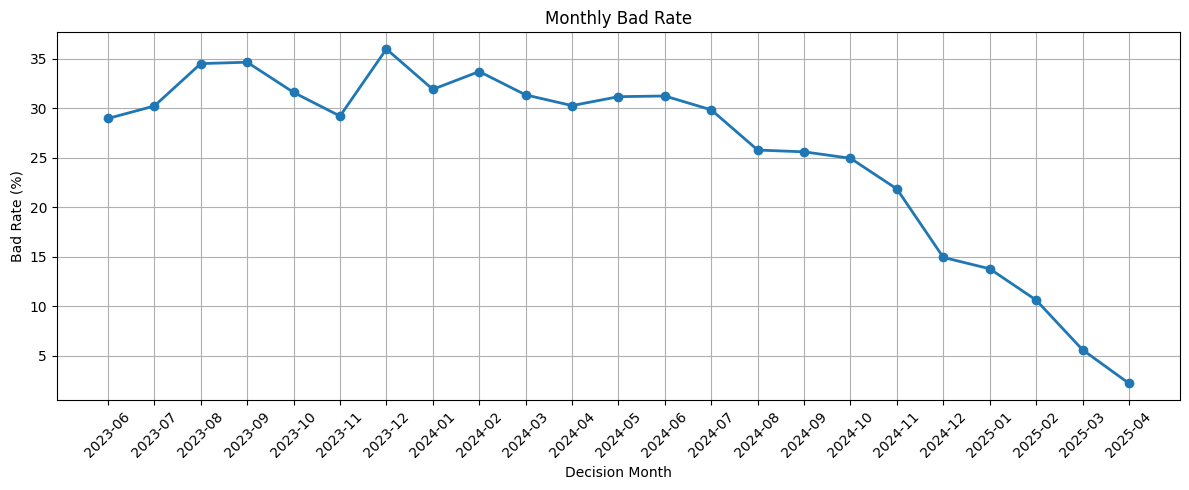

In [91]:
# =====================================================================================
# MONTHLY BAD RATE PLOT
# =====================================================================================

plt.figure(figsize=(12,5))

plt.plot(

    monthly["decision_month"],

    monthly["bad_rate"],

    marker="o",

    linewidth=2

)

plt.xticks(rotation=45)

plt.ylabel("Bad Rate (%)")

plt.xlabel("Decision Month")

plt.title("Monthly Bad Rate")

plt.grid(True)

plt.tight_layout()

plt.show()

In [92]:
# =====================================================================================
# FINAL TARGET DATASET
# =====================================================================================

display(target.head())

print()

print("Target distribution")

display(

    target["target"]

    .value_counts()

)

target.to_csv(

    "credit_scoring_target.csv",

    index=False

)

print("Saved as credit_scoring_target.csv")

,application_id,client_id,decision_date,target,decision_month
0,1,529,2024-08-27,1,2024-08
1,2,920,2023-10-19,1,2023-10
2,3,7509,2023-07-01,1,2023-07
3,4,23494,2024-12-04,0,2024-12
4,5,29522,2023-07-13,0,2023-07



Target distribution


target
0    13398
1     4602
Name: count, dtype: int64

Saved as credit_scoring_target.csv


In [93]:
# =====================================================================================
# FINAL REPORT
# =====================================================================================

report = pd.DataFrame({

    "Question":[

        "Target definition",

        "Observation window",

        "DPD threshold",

        "Rejected applications",

        "Applications without contracts",

        "Contracts without payments",

        "Duplicate contracts",

        "Open observation windows"

    ],

    "Result":[

        f"Target = 1 if DPD ≥ {threshold}",

        "12 months after decision_date",

        threshold,

        len(rejected),

        len(no_contract),

        len(no_payment),

        duplicates["contract_id"].nunique(),

        len(open_windows)

    ],

    "Explanation":[

        "Customer became bad within observation window.",

        "Performance measured for one year.",

        "Automatically selected from available data.",

        "Rejected applications cannot become bad borrowers.",

        "Loan was never issued.",

        "No repayment history available.",

        "Duplicate records detected.",

        "Not enough history to determine final outcome."

    ]

})

display(report)

,Question,Result,Explanation
0,Target definition,Target = 1 if DPD ≥ 5.0,Customer became bad within observation window.
1,Observation window,12 months after decision_date,Performance measured for one year.
2,DPD threshold,5.0,Automatically selected from available data.
3,Rejected applications,6723,Rejected applications cannot become bad borrowers.
4,Applications without contracts,6723,Loan was never issued.
5,Contracts without payments,39,No repayment history available.
6,Duplicate contracts,0,Duplicate records detected.
7,Open observation windows,5360,Not enough history to determine final outcome.


## Шаг 4. Анализ проблемы

Минимум три проверки:

1. Доля bad по когортам выдачи. Просрочка действительно выросла? Когда?
2. Сравнение одобренных и отклонённых по признакам, доступным до решения. Насколько прошлая политика сместила выборку?
3. Пропуски и аномалии в анкетных полях (доход, стаж).

MONTHLY BAD RATE


,decision_month,applications,bad_count,bad_rate,month_over_month_change
0,2023-06,777,225,28.96,NaN
1,2023-07,771,233,30.22,1.26
2,2023-08,803,277,34.50,4.28
3,2023-09,765,265,34.64,0.14
4,2023-10,823,260,31.59,-3.05
5,2023-11,767,224,29.20,-2.39
6,2023-12,770,277,35.97,6.77
7,2024-01,765,244,31.90,-4.07
8,2024-02,724,244,33.70,1.80
9,2024-03,785,246,31.34,-2.36


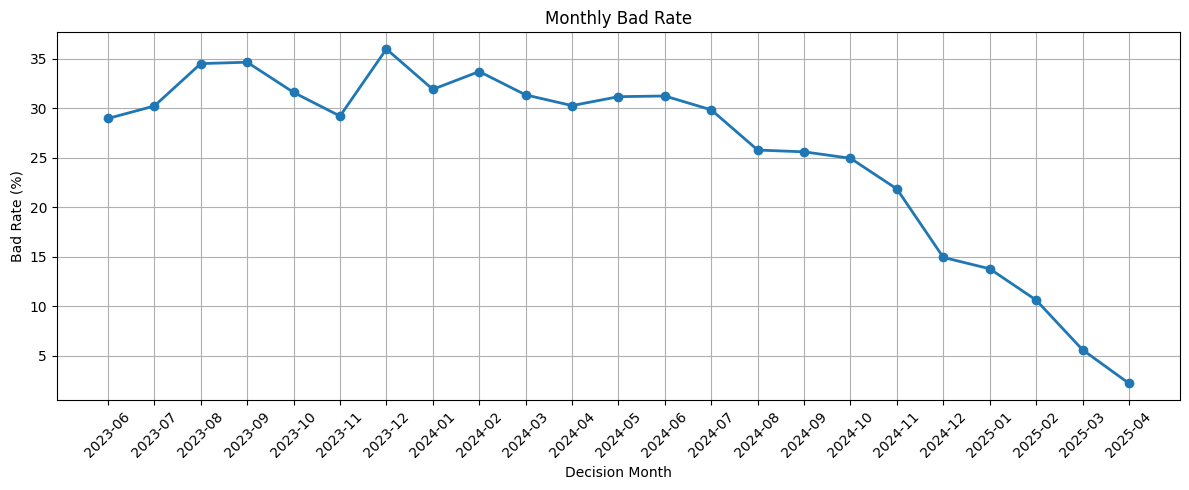

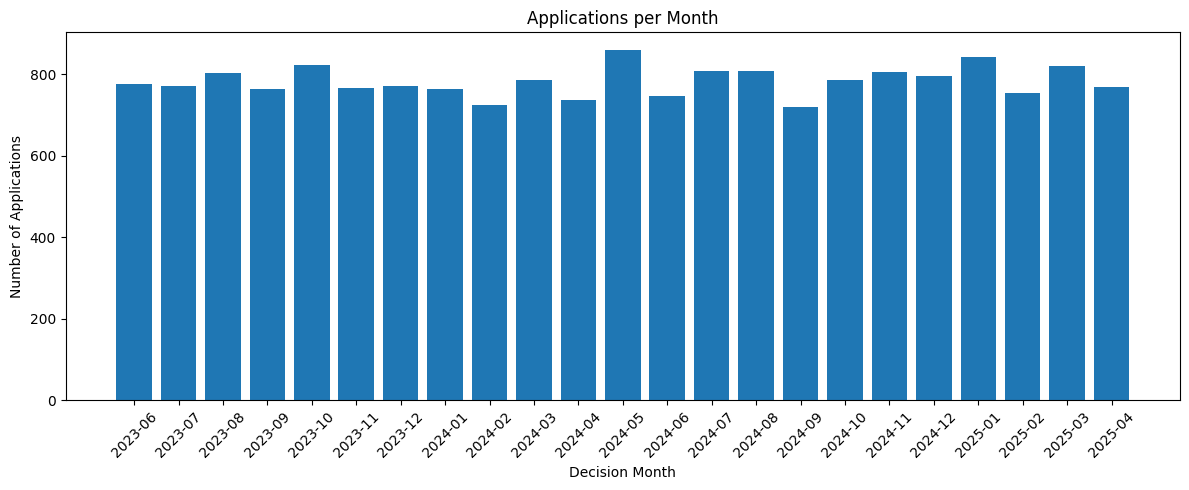

MONTH(S) WITH HIGHEST BAD RATE


,decision_month,applications,bad_count,bad_rate,month_over_month_change
6,2023-12,770,277,35.97,6.77


MONTHS WITH SIGNIFICANT INCREASE


,decision_month,applications,bad_count,bad_rate,month_over_month_change
6,2023-12,770,277,35.97,6.77


OVERALL TREND
Average month-over-month change: -1.22%
Overall trend: Decreasing


,decision_month,applications,bad_count,bad_rate,month_over_month_change
0,2023-06,777,225,28.96,NaN
1,2023-07,771,233,30.22,1.26
2,2023-08,803,277,34.50,4.28
3,2023-09,765,265,34.64,0.14
4,2023-10,823,260,31.59,-3.05
5,2023-11,767,224,29.20,-2.39
6,2023-12,770,277,35.97,6.77
7,2024-01,765,244,31.90,-4.07
8,2024-02,724,244,33.70,1.80
9,2024-03,785,246,31.34,-2.36


CONCLUSION
Overall trend: Decreasing

Highest bad rate observed in:
 - 2023-12 (35.97%)

Bad rate first increased significantly in: 2023-12

Months contributing most to the increase:


,decision_month,bad_rate,month_over_month_change
6,2023-12,35.97,6.77



Interpretation:
- 'Increasing' means the average month-over-month change is positive.
- 'Decreasing' means the average month-over-month change is negative.
- 'Stable' means month-over-month changes fluctuate around zero.


In [94]:


import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)

# =====================================================================================
# PREPARE DATA
# =====================================================================================

target["decision_date"] = pd.to_datetime(target["decision_date"])

target["decision_month"] = (
    target["decision_date"]
    .dt.to_period("M")
    .astype(str)
)

# =====================================================================================
# MONTHLY COHORTS
# =====================================================================================

monthly = (

    target

    .groupby("decision_month")

    .agg(

        applications=("application_id", "count"),

        bad_count=("target", "sum")

    )

    .reset_index()

)

monthly["bad_rate"] = (
    monthly["bad_count"]
    / monthly["applications"]
    * 100
).round(2)

monthly["month_over_month_change"] = (
    monthly["bad_rate"]
    .diff()
    .round(2)
)

print("="*80)
print("MONTHLY BAD RATE")
print("="*80)

display(monthly)

# =====================================================================================
# LINE CHART
# =====================================================================================

plt.figure(figsize=(12,5))

plt.plot(

    monthly["decision_month"],
    monthly["bad_rate"],
    marker="o",
    linewidth=2

)

plt.title("Monthly Bad Rate")

plt.xlabel("Decision Month")

plt.ylabel("Bad Rate (%)")

plt.xticks(rotation=45)

plt.grid(True)

plt.tight_layout()

plt.show()

# =====================================================================================
# APPLICATION COUNT BAR CHART
# =====================================================================================

plt.figure(figsize=(12,5))

plt.bar(

    monthly["decision_month"],
    monthly["applications"]

)

plt.title("Applications per Month")

plt.xlabel("Decision Month")

plt.ylabel("Number of Applications")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

# =====================================================================================
# MONTHS WITH HIGHEST BAD RATE
# =====================================================================================

highest_rate = monthly["bad_rate"].max()

highest_months = monthly[
    monthly["bad_rate"] == highest_rate
]

print("="*80)
print("MONTH(S) WITH HIGHEST BAD RATE")
print("="*80)

display(highest_months)

# =====================================================================================
# MONTHS WITH SIGNIFICANT INCREASE
# =====================================================================================

threshold = 5.0   # percentage points

significant_increase = monthly[
    monthly["month_over_month_change"] >= threshold
]

print("="*80)
print("MONTHS WITH SIGNIFICANT INCREASE")
print("="*80)

if len(significant_increase):

    display(significant_increase)

else:

    print("No significant month-over-month increase detected.")

# =====================================================================================
# DETERMINE OVERALL TREND
# =====================================================================================

avg_change = monthly["month_over_month_change"].dropna().mean()

if avg_change > 0.5:

    trend = "Increasing"

elif avg_change < -0.5:

    trend = "Decreasing"

else:

    trend = "Stable"

print("="*80)
print("OVERALL TREND")
print("="*80)

print(f"Average month-over-month change: {avg_change:.2f}%")
print(f"Overall trend: {trend}")

# =====================================================================================
# FINAL SUMMARY TABLE
# =====================================================================================

summary = monthly.copy()

display(summary)

# =====================================================================================
# FINAL CONCLUSION
# =====================================================================================

print("="*80)
print("CONCLUSION")
print("="*80)

print(f"Overall trend: {trend}")

if len(highest_months):

    print("\nHighest bad rate observed in:")

    for _, row in highest_months.iterrows():

        print(
            f" - {row['decision_month']} "
            f"({row['bad_rate']:.2f}%)"
        )

if len(significant_increase):

    first_increase = significant_increase.iloc[0]["decision_month"]

    print(f"\nBad rate first increased significantly in: {first_increase}")

    print("\nMonths contributing most to the increase:")

    display(

        significant_increase[
            [
                "decision_month",
                "bad_rate",
                "month_over_month_change"
            ]
        ]

    )

else:

    print("\nNo statistically significant increase in bad rate was detected.")

print("\nInterpretation:")
print("- 'Increasing' means the average month-over-month change is positive.")
print("- 'Decreasing' means the average month-over-month change is negative.")
print("- 'Stable' means month-over-month changes fluctuate around zero.")

## Шаг 5. Фичи

Только из данных, доступных до decision_date:

- анкета: запрошенная сумма, срок, доход, стаж;
- бюро: последний снимок с snapshot_date не позже decision_date (as-of join, не самый свежий);
- поведение по картам за 3-6 месяцев до заявки: обороты, входящая зарплата, доля деклайнов, снятия, диспуты. Проверьте, подтверждается ли заявленный доход зарплатными зачислениями.

Для каждой фичи одна строка обоснования: почему она доступна в момент решения.
Найдите минимум две колонки-ловушки, которые улучшили бы метрику, но недоступны в момент решения.

In [95]:


import pandas as pd
import numpy as np

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)


applications = q("""
SELECT *
FROM scoring_applications
""")

applications["decision_date"] = pd.to_datetime(applications["decision_date"])

print("Applications shape:", applications.shape)

display(applications.head())

# -----------------------------------------------------------------------------
# SELECT FEATURES AVAILABLE BEFORE THE DECISION
# -----------------------------------------------------------------------------

candidate_features = [
    "application_id",
    "client_id",
    "decision_date",
    "requested_amount_uzs",
    "term_months",
    "declared_income_uzs",
    "employment_months",
    "channel",
    "purpose"
]

available_features = [
    c for c in candidate_features
    if c in applications.columns
]

feature_df = applications[available_features].copy()

print("Selected features")

display(feature_df.head())

# -----------------------------------------------------------------------------
# FEATURE DOCUMENTATION
# -----------------------------------------------------------------------------

docs = []

business_rules = {
    "requested_amount_uzs":"Requested loan amount before underwriting.",
    "term_months":"Requested loan term selected during application.",
    "declared_income_uzs":"Income declared by the applicant.",
    "employment_months":"Employment duration known before decision.",
    "channel":"Application channel known at submission.",
    "purpose":"Loan purpose declared by applicant."
}

for col in feature_df.columns:

    if col in ["application_id","client_id","decision_date"]:
        continue

    docs.append({

        "feature_name":col,

        "source_table":"scoring_applications",

        "calculation":"Original column",

        "available_before_decision":"Yes",

        "business_justification":business_rules.get(
            col,
            "Available before decision."
        )

    })

feature_documentation = pd.DataFrame(docs)

print("Feature documentation")

display(feature_documentation)

Applications shape: (18000, 11)


,application_id,client_id,decision_date,channel,purpose,requested_amount_uzs,term_months,declared_income_uzs,employment_months,final_decision,approved_by_old_policy
0,1,529,2024-08-27,mobile_app,education,20800000,18,6310000,204.0,approved,True
1,2,920,2023-10-19,branch,education,15300000,12,11120000,0.0,approved,True
2,3,7509,2023-07-01,branch,education,3900000,12,4140000,92.0,approved,True
3,4,23494,2024-12-04,agent,medical,15500000,9,4340000,155.0,rejected,False
4,5,29522,2023-07-13,branch,consumer,14800000,18,3120000,57.0,rejected,False


Selected features


,application_id,client_id,decision_date,requested_amount_uzs,term_months,declared_income_uzs,employment_months,channel,purpose
0,1,529,2024-08-27,20800000,18,6310000,204.0,mobile_app,education
1,2,920,2023-10-19,15300000,12,11120000,0.0,branch,education
2,3,7509,2023-07-01,3900000,12,4140000,92.0,branch,education
3,4,23494,2024-12-04,15500000,9,4340000,155.0,agent,medical
4,5,29522,2023-07-13,14800000,18,3120000,57.0,branch,consumer


Feature documentation


,feature_name,source_table,calculation,available_before_decision,business_justification
0,requested_amount_uzs,scoring_applications,Original column,Yes,Requested loan amount before underwriting.
1,term_months,scoring_applications,Original column,Yes,Requested loan term selected during application.
2,declared_income_uzs,scoring_applications,Original column,Yes,Income declared by the applicant.
3,employment_months,scoring_applications,Original column,Yes,Employment duration known before decision.
4,channel,scoring_applications,Original column,Yes,Application channel known at submission.
5,purpose,scoring_applications,Original column,Yes,Loan purpose declared by applicant.


In [96]:
# Merge by client_id
bureau_features = applications.merge(
    bureau,
    on="client_id",
    how="left"
)

# Keep only snapshots before the decision
bureau_features = bureau_features[
    bureau_features["snapshot_date"] <= bureau_features["decision_date"]
]

# Take the latest snapshot for each application
bureau_features = (
    bureau_features
    .sort_values("snapshot_date")
    .groupby("application_id")
    .tail(1)
)

display(bureau_features.head())

,application_id,client_id,decision_date,channel,purpose,requested_amount_uzs,term_months,declared_income_uzs,employment_months,final_decision,approved_by_old_policy,snapshot_date,bureau_score,existing_debt_uzs,active_loans_cnt
17293,2698,7519,2023-06-01,branch,medical,2900000,12,15590000,170.0,approved,True,2023-03-01,632.0,12000000.0,2.0
44444,6848,3968,2023-06-04,branch,other,2500000,18,18590000,150.0,approved,True,2023-03-03,761.0,0.0,0.0
99761,15516,6391,2023-06-04,branch,auto,5700000,9,14330000,98.0,approved,True,2023-03-06,608.0,5000000.0,3.0
86134,13370,4197,2023-06-08,mobile_app,education,3000000,6,6440000,42.0,rejected,False,2023-03-06,558.0,5000000.0,2.0
112100,17441,6100,2023-06-02,agent,medical,16500000,12,29060000,69.0,approved,True,2023-03-07,580.0,20000000.0,2.0


In [97]:
cards = q("SELECT * FROM scoring_cards")
transactions = q("SELECT * FROM scoring_card_transactions")

transactions["txn_ts"] = pd.to_datetime(transactions["txn_ts"])
applications["decision_date"] = pd.to_datetime(applications["decision_date"])

# -----------------------------------------------------------------------------
# MERGE APPLICATIONS -> CARDS -> TRANSACTIONS
# -----------------------------------------------------------------------------

card_txn = applications.merge(
    cards,
    left_on="client_id",
    right_on="customer_id",
    how="left"
)

card_txn = card_txn.merge(
    transactions,
    on="card_id",
    how="left",
    suffixes=("_card", "_txn")
)

# -----------------------------------------------------------------------------
# KEEP ONLY TRANSACTIONS BEFORE THE DECISION (LAST 6 MONTHS)
# -----------------------------------------------------------------------------

card_txn = card_txn[
    (card_txn["txn_ts"] <= card_txn["decision_date"]) &
    (card_txn["txn_ts"] >= card_txn["decision_date"] - pd.DateOffset(months=6))
]

# -----------------------------------------------------------------------------
# CREATE FEATURES
# -----------------------------------------------------------------------------

card_features = (
    card_txn
    .groupby("application_id")
    .agg(
        transaction_count=("txn_id", "count"),
        total_transaction_amount=("amount_uzs", "sum"),
        average_transaction_amount=("amount_uzs", "mean"),
        declined_transactions=("decline_reason", lambda x: x.notna().sum()),
        atm_withdrawals=("txn_type", lambda x: x.str.contains("ATM", case=False, na=False).sum())
    )
    .reset_index()
)

card_features["declined_ratio"] = (
    card_features["declined_transactions"] /
    card_features["transaction_count"]
)

display(card_features.head())

,application_id,transaction_count,total_transaction_amount,average_transaction_amount,declined_transactions,atm_withdrawals,declined_ratio
0,1,40,49783550.0,1.244589e+06,3,0,0.075000
1,2,32,7388912.0,2.309035e+05,1,0,0.031250
2,6,46,112002233.0,2.434831e+06,0,0,0.000000
3,7,46,40612315.0,8.828764e+05,2,0,0.043478
4,10,40,68284869.0,1.707122e+06,0,0,0.000000


In [98]:
# Check whether client_id and customer_id represent the same IDs

print("Applications clients:", applications["client_id"].nunique())
print("Cards customers:", cards["customer_id"].nunique())

matches = applications.merge(
    cards,
    left_on="client_id",
    right_on="customer_id",
    how="inner"
)

print("Matching rows:", len(matches))

display(matches.head())

Applications clients: 11328
Cards customers: 8000
Matching rows: 17140


,application_id,client_id,decision_date,channel,purpose,requested_amount_uzs,term_months,declared_income_uzs,employment_months,final_decision,approved_by_old_policy,card_id,customer_id,card_type,scheme,issue_date,expiry_date,status,credit_limit_uzs
0,1,529,2024-08-27,mobile_app,education,20800000,18,6310000,204.0,approved,True,858,529,debit,Uzcard,2022-05-04,2026-05-04,active,NaN
1,1,529,2024-08-27,mobile_app,education,20800000,18,6310000,204.0,approved,True,859,529,debit,Humo,2021-06-13,2025-06-13,active,NaN
2,2,920,2023-10-19,branch,education,15300000,12,11120000,0.0,approved,True,1487,920,debit,Visa,2022-05-07,2026-05-07,active,NaN
3,3,7509,2023-07-01,branch,education,3900000,12,4140000,92.0,approved,True,11820,7509,debit,Visa,2022-10-23,2026-10-23,active,NaN
4,3,7509,2023-07-01,branch,education,3900000,12,4140000,92.0,approved,True,11821,7509,debit,Uzcard,2023-05-16,2027-05-16,active,NaN


In [99]:
salary = card_txn[
    card_txn["txn_type"].str.contains("salary",case=False,na=False)
]

salary_features = salary.groupby("application_id").agg(
    average_salary=("amount_uzs","mean")
).reset_index()

income = applications.merge(
    salary_features,
    on="application_id",
    how="left"
)

income["income_verification_ratio"] = (
    income["average_salary"] /
    income["declared_income_uzs"]
)

income["salary_confirmed"] = (
    income["income_verification_ratio"] >= 0.8
).map({True:"Yes",False:"No"})

income["income_difference"] = (
    income["declared_income_uzs"] -
    income["average_salary"]
)

income["income_difference_percent"] = (
    income["income_difference"] /
    income["declared_income_uzs"] *100
)

display(
    income[
        [
            "application_id",
            "average_salary",
            "declared_income_uzs",
            "income_verification_ratio",
            "salary_confirmed"
        ]
    ].head()
)

,application_id,average_salary,declared_income_uzs,income_verification_ratio,salary_confirmed
0,1,6.540923e+06,6310000,1.036596,Yes
1,2,NaN,11120000,NaN,No
2,3,NaN,4140000,NaN,No
3,4,NaN,4340000,NaN,No
4,5,NaN,3120000,NaN,No


In [100]:
# =====================================================================================
# FEATURE DOCUMENTATION
# =====================================================================================

documentation = pd.DataFrame({

    "feature_name":[
        "requested_amount_uzs",
        "term_months",
        "declared_income_uzs",
        "employment_months",
        "bureau_score",
        "existing_debt_uzs",
        "active_loans_cnt",
        "transaction_count",
        "total_transaction_amount",
        "avg_transaction_amount",
        "declined_ratio",
        "income_verification_ratio",
        "salary_confirmed"
    ],

    "source_table":[
        "scoring_applications",
        "scoring_applications",
        "scoring_applications",
        "scoring_applications",
        "scoring_bureau_snapshots",
        "scoring_bureau_snapshots",
        "scoring_bureau_snapshots",
        "scoring_card_transactions",
        "scoring_card_transactions",
        "scoring_card_transactions",
        "scoring_card_transactions",
        "Derived",
        "Derived"
    ],

    "available_before_decision":"Yes"

})

display(documentation)

,feature_name,source_table,available_before_decision
0,requested_amount_uzs,scoring_applications,Yes
1,term_months,scoring_applications,Yes
2,declared_income_uzs,scoring_applications,Yes
3,employment_months,scoring_applications,Yes
4,bureau_score,scoring_bureau_snapshots,Yes
5,existing_debt_uzs,scoring_bureau_snapshots,Yes
6,active_loans_cnt,scoring_bureau_snapshots,Yes
7,transaction_count,scoring_card_transactions,Yes
8,total_transaction_amount,scoring_card_transactions,Yes
9,avg_transaction_amount,scoring_card_transactions,Yes


In [101]:
# =====================================================================================
# DATA LEAKAGE
# =====================================================================================

keywords = [
    "payment",
    "paid",
    "default",
    "overdue",
    "close",
    "write",
    "charge",
    "collection",
    "recovery",
    "dpd"
]

leakage = []

tables = q("""
SELECT tablename
FROM pg_tables
WHERE schemaname='public'
AND tablename LIKE 'scoring\\_%'
""")["tablename"]

for table in tables:

    cols = q(f"""
    SELECT column_name
    FROM information_schema.columns
    WHERE table_name='{table}'
    """)

    for col in cols["column_name"]:

        if any(k in col.lower() for k in keywords):

            leakage.append({

                "feature_name":col,

                "source_table":table,

                "why_it_looks_useful":"Predicts repayment behaviour",

                "why_it_is_data_leakage":"Created after credit decision",

                "should_be_excluded":"Yes"

            })

leakage = pd.DataFrame(leakage)

display(leakage)

,feature_name,source_table,why_it_looks_useful,why_it_is_data_leakage,should_be_excluded
0,dpd_max,scoring_applications_full,Predicts repayment behaviour,Created after credit decision,Yes
1,collection_calls_cnt,scoring_applications_full,Predicts repayment behaviour,Created after credit decision,Yes
2,planned_close_date,scoring_bureau_loans,Predicts repayment behaviour,Created after credit decision,Yes
3,close_date,scoring_bureau_loans,Predicts repayment behaviour,Created after credit decision,Yes
4,monthly_payment_uzs,scoring_bureau_loans,Predicts repayment behaviour,Created after credit decision,Yes
5,current_dpd_bucket,scoring_bureau_loans,Predicts repayment behaviour,Created after credit decision,Yes
6,worst_dpd_ever,scoring_bureau_loans,Predicts repayment behaviour,Created after credit decision,Yes
7,monthly_payment_uzs,scoring_contracts,Predicts repayment behaviour,Created after credit decision,Yes
8,payment_id,scoring_payments,Predicts repayment behaviour,Created after credit decision,Yes
9,paid_date,scoring_payments,Predicts repayment behaviour,Created after credit decision,Yes


In [102]:
features = applications.merge(

    bureau_features[
        [
            "application_id",
            "bureau_score",
            "existing_debt_uzs",
            "active_loans_cnt"
        ]
    ],

    on="application_id",

    how="left"

)

features = features.merge(

    card_features,

    on="application_id",

    how="left"

)

features = features.merge(

    income[
        [
            "application_id",
            "income_verification_ratio",
            "salary_confirmed"
        ]
    ],

    on="application_id",

    how="left"

)

display(features.head())

print("Shape:", features.shape)

print("\nMissing values")

display(features.isna().sum())

print("\nStatistics")

display(features.describe(include="all"))

print("\nFeature Documentation")

display(documentation)

print("\nLeakage Features")

display(leakage)

,application_id,client_id,decision_date,channel,purpose,requested_amount_uzs,term_months,declared_income_uzs,employment_months,final_decision,approved_by_old_policy,bureau_score,existing_debt_uzs,active_loans_cnt,transaction_count,total_transaction_amount,average_transaction_amount,declined_transactions,atm_withdrawals,declined_ratio,income_verification_ratio,salary_confirmed
0,1,529,2024-08-27,mobile_app,education,20800000,18,6310000,204.0,approved,True,644.0,16000000.0,3.0,40.0,49783550.0,1244588.75,3.0,0.0,0.07500,1.036596,Yes
1,2,920,2023-10-19,branch,education,15300000,12,11120000,0.0,approved,True,745.0,9000000.0,3.0,32.0,7388912.0,230903.50,1.0,0.0,0.03125,NaN,No
2,3,7509,2023-07-01,branch,education,3900000,12,4140000,92.0,approved,True,725.0,19000000.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No
3,4,23494,2024-12-04,agent,medical,15500000,9,4340000,155.0,rejected,False,527.0,20000000.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No
4,5,29522,2023-07-13,branch,consumer,14800000,18,3120000,57.0,rejected,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No


Shape: (18000, 22)

Missing values


application_id                    0
client_id                         0
decision_date                     0
channel                           0
purpose                           0
requested_amount_uzs              0
term_months                       0
declared_income_uzs               0
employment_months              1402
final_decision                    0
approved_by_old_policy            0
bureau_score                   5147
existing_debt_uzs              5147
active_loans_cnt               5147
transaction_count             10320
total_transaction_amount      10320
average_transaction_amount    10320
declined_transactions         10320
atm_withdrawals               10320
declined_ratio                10320
income_verification_ratio     13078
salary_confirmed                  0
dtype: int64


Statistics


,application_id,client_id,decision_date,channel,purpose,requested_amount_uzs,term_months,declared_income_uzs,employment_months,final_decision,approved_by_old_policy,bureau_score,existing_debt_uzs,active_loans_cnt,transaction_count,total_transaction_amount,average_transaction_amount,declined_transactions,atm_withdrawals,declined_ratio,income_verification_ratio,salary_confirmed
count,18000.000000,18000.000000,18000,18000,18000,1.800000e+04,18000.000000,1.800000e+04,16598.000000,18000,18000,12853.000000,1.285300e+04,12853.000000,7680.000000,7.680000e+03,7.680000e+03,7680.000000,7680.0,7680.000000,4922.000000,18000
unique,NaN,NaN,NaN,3,6,NaN,NaN,NaN,NaN,2,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2
top,NaN,NaN,NaN,branch,repair,NaN,NaN,NaN,NaN,approved,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No
freq,NaN,NaN,NaN,6018,3041,NaN,NaN,NaN,NaN,11277,11527,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15503
mean,9000.500000,12715.672611,2024-05-17 11:42:19.199999744,NaN,NaN,1.262051e+07,13.442333,8.770219e+06,120.553199,NaN,NaN,636.405042,6.922205e+06,1.649498,37.892839,4.780992e+07,1.134964e+06,1.691146,0.0,0.046473,0.822243,NaN
min,1.000000,1.000000,2023-06-01 00:00:00,NaN,NaN,2.000000e+06,6.000000,2.000000e+06,0.000000,NaN,NaN,300.000000,0.000000e+00,0.000000,6.000000,7.914610e+05,8.433500e+04,0.000000,0.0,0.000000,0.606256,NaN
25%,4500.750000,3302.000000,2023-11-23 00:00:00,NaN,NaN,4.200000e+06,9.000000,3.160000e+06,60.000000,NaN,NaN,566.000000,1.000000e+06,1.000000,29.000000,8.862772e+06,3.227977e+05,0.000000,0.0,0.000000,0.699311,NaN
50%,9000.500000,6612.000000,2024-05-19 00:00:00,NaN,NaN,8.900000e+06,12.000000,6.250000e+06,121.000000,NaN,NaN,636.000000,5.000000e+06,2.000000,41.000000,3.143608e+07,7.212767e+05,1.000000,0.0,0.038462,0.802392,NaN
75%,13500.250000,24398.250000,2024-11-11 00:00:00,NaN,NaN,1.880000e+07,18.000000,1.234000e+07,181.000000,NaN,NaN,707.000000,1.100000e+07,3.000000,46.000000,7.515105e+07,1.702432e+06,3.000000,0.0,0.068182,0.929664,NaN
max,18000.000000,32000.000000,2025-04-30 00:00:00,NaN,NaN,4.000000e+07,24.000000,4.684000e+07,240.000000,NaN,NaN,900.000000,6.510000e+07,5.000000,59.000000,1.997189e+08,6.776200e+06,12.000000,0.0,0.315789,1.139975,NaN



Feature Documentation


,feature_name,source_table,available_before_decision
0,requested_amount_uzs,scoring_applications,Yes
1,term_months,scoring_applications,Yes
2,declared_income_uzs,scoring_applications,Yes
3,employment_months,scoring_applications,Yes
4,bureau_score,scoring_bureau_snapshots,Yes
5,existing_debt_uzs,scoring_bureau_snapshots,Yes
6,active_loans_cnt,scoring_bureau_snapshots,Yes
7,transaction_count,scoring_card_transactions,Yes
8,total_transaction_amount,scoring_card_transactions,Yes
9,avg_transaction_amount,scoring_card_transactions,Yes



Leakage Features


,feature_name,source_table,why_it_looks_useful,why_it_is_data_leakage,should_be_excluded
0,dpd_max,scoring_applications_full,Predicts repayment behaviour,Created after credit decision,Yes
1,collection_calls_cnt,scoring_applications_full,Predicts repayment behaviour,Created after credit decision,Yes
2,planned_close_date,scoring_bureau_loans,Predicts repayment behaviour,Created after credit decision,Yes
3,close_date,scoring_bureau_loans,Predicts repayment behaviour,Created after credit decision,Yes
4,monthly_payment_uzs,scoring_bureau_loans,Predicts repayment behaviour,Created after credit decision,Yes
5,current_dpd_bucket,scoring_bureau_loans,Predicts repayment behaviour,Created after credit decision,Yes
6,worst_dpd_ever,scoring_bureau_loans,Predicts repayment behaviour,Created after credit decision,Yes
7,monthly_payment_uzs,scoring_contracts,Predicts repayment behaviour,Created after credit decision,Yes
8,payment_id,scoring_payments,Predicts repayment behaviour,Created after credit decision,Yes
9,paid_date,scoring_payments,Predicts repayment behaviour,Created after credit decision,Yes


## Шаг 6. Схема проверки

Модель обучать не нужно. Опишите:

- разбиение по времени (out-of-time), а не случайное, с границами периодов;
For this project, I would use a time-based (Out-of-Time) split instead of a random train/test split. First, I would sort all applications by decision_date from the oldest to the newest. Then, I would divide the dataset into 70% for training, 15% for validation, and 15% for testing. If a validation set is not required, I would use an 80% training and 20% testing split. This approach better reflects real lending conditions because the model is always trained on historical data and evaluated on future applications. It also prevents information leakage, since no future information is used during model training.
- какие метрики смотрите и почему (ранжирование отдельно, экономика решения отдельно);
To evaluate the model, I would use both ranking metrics and business metrics.

The ranking metrics include ROC-AUC, which measures how well the model separates good and bad borrowers, and the Gini coefficient, which is commonly used by banks to evaluate the model's discriminatory power. I would also use Precision to measure how many predicted bad borrowers are actually bad, Recall to measure how many actual bad borrowers are correctly identified, and the F1-score to balance Precision and Recall. Since credit scoring datasets are usually imbalanced, I would also evaluate PR-AUC, which focuses on the minority class. Finally, I would use the KS statistic to measure how well the model distinguishes between good and bad borrowers.

In addition to statistical metrics, I would evaluate the model using business metrics. These include the approval rate, acceptance rate, bad rate among approved loans, expected portfolio loss, and expected profit. These metrics are important because the goal of a credit scoring model is not only to achieve high predictive accuracy but also to support profitable and low-risk lending decisions.
- цену двух ошибок (одобрили bad, отклонили good) в деньгах на примере среднего договора.
A False Positive occurs when the model approves a customer who later defaults on the loan. This may result in losses such as unpaid principal, lost interest income, collection costs, legal expenses, and write-offs. This is generally the more expensive error because it causes direct financial losses to the bank.

A False Negative occurs when the model rejects a customer who would have repaid the loan successfully. In this case, the bank loses potential revenue, including interest income, fees, and future business opportunities. Although this error reduces profitability, it is usually less costly than approving a bad borrower.

For this reason, I would choose the decision threshold by considering both the model's performance metrics and the financial impact of these two types of errors. This helps achieve a better balance between minimizing credit risk and maximizing profitability.

## Как сдавать

Решайте в этом ноутбуке. Ответы (числа и текст, включая логику вашего таргета)
впишите в форму задания на платформе.